# Initalize libraries

## Import libraries

In [63]:
import sys, os
import time
from os.path import join
from os import path
from importlib import reload
from getpass import getuser
from glob import glob

import xarray as xr
import h5py
from tqdm.auto import tqdm

sys.path.append("/asap3/petra3/gpfs/p04/2023/data/11019143/shared/ck/library")

import numpy as np
import matplotlib.pyplot as plt
import scipy
import fabio
import skimage.morphology

# Open nexus files
from nexusformat.nexus import *

from scipy.ndimage.filters import gaussian_filter

# dask
import dask
import dask.array as da
from dask.distributed import Client

# image registration
from dipy.align.transforms import AffineTransform2D, TranslationTransform2D
from dipy.align.imaffine import MutualInformationMetric, AffineRegistration

# pyFAI
import pyFAI
from pyFAI.azimuthalIntegrator import AzimuthalIntegrator
from pyFAI.detectors import Detector

# Self-written libraries
import reconstruct as reco
import fthcore as fth
import support_functions as sup
from interactive import cimshow
import interactive

# Gifs
import imageio

from scipy import stats

plt.rcParams["figure.constrained_layout.use"] = True  # replaces plt.tight_layout

import reconstruct as reco
import reconstruct_rb as rec

In [64]:
# Is there a GPU?
try:
    # Cupy
    import cupy as cp
    import cupyx as cpx

    GPU = True

    print("GPU available")

    # Self-written library
    import CCI_core_cupy as cci
    import Phase_Retrieval as PhR
except:
    GPU = False
    import CCI_core as cci

    print("GPU unavailable")

GPU available


In [65]:
# interactive plotting
import ipywidgets

%matplotlib widget

# Auto formatting of cells
%load_ext jupyter_black

The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black


## Experiment specific Functions

In [66]:
PROPOSAL = 11019143
USER = getuser()

### Loading data

In [67]:
BASEFOLDER = "/asap3/petra3/gpfs/p04/2023/data/%s/" % PROPOSAL
subfolder = "FGT"
sample_name = "2310_FGT"


# Load image files
def load_images(im_id):
    """
    Load ccd images from nxs files
    """

    fname = join(BASEFOLDER, "raw", subfolder, "%s_%05d.nxs" % (sample_name, im_id))

    with nxload(fname) as f:
        im_out = np.array(f["scan"]["data"]["ccd"][()])
        print("Loaded: %s (%d frames)" % (fname, im_out.shape[0]))
    return im_out.squeeze()


# Load any kind of data from collection
def load_collection(scan_id, key):
    """
    Load from collection in nxs files
    """

    fname = join(BASEFOLDER, "raw", subfolder, "%s_%05d.nxs" % (sample_name, scan_id))

    with nxload(fname) as f:
        data = f["scan"]["instrument"]["collection"][key][()]
        print("Loaded key %s of %s" % (key, fname))
    return data


# Load any kind of data from collection
def load_energy(scan_id):
    """
    Load energy from nxs files
    """

    fname = join(BASEFOLDER, "raw", subfolder, "%s_%05d.nxs" % (sample_name, scan_id))

    with nxload(fname) as f:
        data = f["scan"]["instrument"]["mono"]["energy"][()]
        print("Loaded: %s" % (fname))
    return data


# Load any kind of data from measurements
def load_data(scan_id, key):
    """
    Load from data in nxs files
    """
    fname = join(BASEFOLDER, "raw", subfolder, "%s_%05d.nxs" % (sample_name, scan_id))

    with nxload(fname) as f:
        data = f["scan"]["data"][key][()]
        print("Loaded key %s of %s" % (key, fname))
    return data


# Full image loading procedure
def load_processing(im_id):
    """
    Loads images, averaging of two individual images saved in scan, padding to square shape
    """

    # Load data
    images = load_images(im_id)

    # Zeropad to get square shape
    images = sup.padding(images)

    # Calculate mean
    if images.ndim > 2:
        image = np.mean(images, axis=0)
    else:
        image = images.copy()

    return image, images

### Loading, saving fth & cdi data

In [68]:
# Saving of log files for fth and cdi recos
def save_fth_h5():
    # Save h5
    data = {}
    data["im_id"] = im_id
    data["topo_id"] = topo_id
    data["topo_centered"] = topo_c
    data["im_centered"] = im_c
    data["holo"] = holo
    data["sum_b"] = sum_b
    data["recon"] = recon
    data["factor"] = factor
    data["offset"] = offset
    data["center"] = center
    data["roi"] = roi
    data["prop_dist"] = prop_dist
    data["phase"] = phase
    data["mask_bs"] = mask_bs
    data["bs_diam"] = bs_diam

    filename = join(
        folder_general, "Logs", "Data_ImId_%04d_RefId_%s_%s" % (im_id, topo_id, USER)
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)


def save_cdi_h5():
    # Save h5
    data = {}
    data["im_id"] = im_id
    data["topo_id"] = topo_id
    data["pos"] = pos
    data["neg"] = neg
    data["factor"] = factor
    data["offset"] = offset
    data["center"] = center
    data["roi"] = roi
    data["prop_dist"] = prop_dist_cdi
    data["phase"] = phase_cdi
    data["mask_bs"] = mask_bs
    data["bs_diam"] = bs_diam_cdi
    data["supportmask"] = supportmask
    data["mask_pixel"] = mask_pixel
    data["p"] = p
    data["n"] = n
    data["p_pc"] = p_pc
    data["n_pc"] = n_pc

    filename = join(
        folder_general,
        "Logs",
        "Data_ImId_%04d_RefId_%s_cdi_%s" % (im_id, topo_id, USER),
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)
    return


def save_topo_holo(topo_c, pos_id, neg_id):
    """
    Save only topo holos which can be later used for single helicity reconstructions
    """
    data = {}
    data["pos_id"] = pos_id
    data["neg_id"] = neg_id
    data["topo"] = topo_c

    filename = join(
        folder_general,
        "Topos",
        "Topo_ImId_%04d_RefId_%04d_cdi_%s" % (pos_id, neg_id, USER),
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)
    return


def load_topo_holo(pos_id, neg_id):
    """
    Load topo holos for single helicity reconstructions
    """
    fname = join(
        folder_general,
        "Topos",
        "Topo_ImId_%04d_RefId_%04d_cdi_%s.hdf5" % (pos_id, neg_id, USER),
    )

    with h5py.File(fname, "r") as f:
        im_out = f["topo"][()]
    return im_out


def load_cdi(im_id, topo_id):
    """
    Load cdi dataset
    """
    fname = join(
        folder_general,
        "Logs",
        "Data_ImId_%04d_RefId_%s_cdi_%s.hdf5" % (im_id, topo_id, USER),
    )

    with h5py.File(fname, "r") as f:
        data_cdi = {}
        data_cdi["im_id"] = f["im_id"][()]
        data_cdi["topo_id"] = f["topo_id"][()]
        data_cdi["topo_centered"] = f["topo_centered"][()]
        data_cdi["im_centered"] = f["im_centered"][()]
        data_cdi["pos"] = f["pos"][()]
        data_cdi["neg"] = f["neg"][()]
        data_cdi["recon"] = f["recon"][()]
        data_cdi["factor"] = f["factor"][()]
        data_cdi["offset"] = f["offset"][()]
        data_cdi["center"] = f["center"][()]
        data_cdi["roi"] = f["roi"][()]
        data_cdi["prop_dist"] = f["prop_dist"][()]
        data_cdi["phase"] = f["phase"][()]
        data_cdi["mask_bs"] = f["mask_bs"][()]
        data_cdi["bs_diam"] = f["bs_diam"][()]
        data_cdi["supportmask"] = f["supportmask"][()]
        data_cdi["mask_pixel"] = f["mask_pixel"][()]
        data_cdi["p"] = f["p"][()]
        data_cdi["n"] = f["n"][()]
        data_cdi["p_pc"] = f["p_pc"][()]
        data_cdi["n_pc"] = f["n_pc"][()]
        data_cdi["gamma_p"] = f["gamma_p"][()]
        data_cdi["gamma_n"] = f["gamma_n"][()]
    return data_cdi

### Masking

In [69]:
from matplotlib.widgets import PolygonSelector
from matplotlib.path import Path


def create_single_polygon_mask(shape, coordinates):
    """
    Creates a polygon mask from coordinates of corner points

    Parameter
    =========
    shape : int tuple
        shape/dimension of output array
    coordinates: nested list
        coordinates of polygon corner points [[yc_1,xc_1],[yc_2,xc_2],...]


    Output
    ======
    mask: array
        binary mask where filled polygon is "1"
    ======
    author: ck 2023
    """

    x, y = np.meshgrid(np.arange(shape[0]), np.arange(shape[1]))
    x, y = x.flatten(), y.flatten()

    points = np.vstack((x, y)).T

    path = Path(coordinates)
    mask = path.contains_points(points)
    mask = mask.reshape(shape)
    return mask


def create_polygon_mask(shape, coordinates):
    """
    Creates multiple polygon masks from set of coordinates of corner points

    Parameter
    =========
    shape : int tuple
        shape/dimension of output array
    coordinates: nested list
        coordinates of polygon corner points for multiple polygons
        [[[yc_1,xc_1],[yc_2,xc_2],...],[[yc_1,xc_1],[yc_2,xc_2],...]]

    Output
    ======
    mask: array
        binary mask where filled polygons are "1"
    ======
    author: ck 2023
    """

    if len(coordinates) == 1:
        mask = create_single_polygon_mask(shape, coordinates[0])

    # Loop over coordinates
    elif len(coordinates) > 1:
        mask = np.zeros(shape)
        for coord in coordinates:
            mask = mask + create_single_polygon_mask(shape, coord)
            mask[mask > 1] = 1

    return mask


def load_poly_masks(polygon_name_list):
    """
    Loads set of polygon masks based on stored coordinates

    Parameter
    =========
    polygon_name_list : list
        keys of different mask coordinates to load

    Output
    ======
    mask: array
        binary mask where filled polygons are "1"
    ======
    author: ck 2023
    """

    mask = []

    # Load dictionary of coordinates
    mask_coordinates = load_poly_coordinates()

    # Loop over relevant mask keys
    for polygon_name in polygon_name_list:
        coord = mask_coordinates[polygon_name]
        mask.append(create_polygon_mask(im_c.shape, coord).astype(float))

    # Combine all individual mask layers
    mask = np.array(mask)
    mask = np.sum(mask, axis=0)
    mask[mask > 1] = 1

    return mask

In [70]:
# Still experimental
def automated_beamstop(hologram, grad_thres, radius, expand, method="intensity"):
    # Different methods for filtering of beamstop
    if method == "intensity":
        # Some filters
        pass
    elif method == "gradient":
        hologram = np.mean(np.abs(np.gradient(hologram)), axis=0)

    # Thresholding with gradient
    hologram_mask = hologram < grad_thres

    # Draw beamstop only up to given radius
    hologram_mask = hologram_mask * cci.circle_mask(
        image.shape,
        [image.shape[0] / 2, image.shape[1] / 2],
        radius,
        sigma=None,
    )
    hologram_mask = hologram_mask.astype(bool)

    # Morphological operations to filter reference modulations as these also lead to strong intensity gradients
    # close the "dots" of the ref modulations
    footprint = skimage.morphology.disk(2)
    hologram_mask = skimage.morphology.erosion(hologram_mask, footprint)

    # Filter remainings of ref modulations
    hologram_mask = skimage.morphology.remove_small_objects(
        hologram_mask, min_size=2000
    )

    # Expand Mask
    footprint = skimage.morphology.disk(expand)
    hologram_mask = skimage.morphology.dilation(hologram_mask, footprint)

    # Fill up small holes in the mask
    hologram_mask = scipy.ndimage.binary_fill_holes(
        hologram_mask, structure=np.ones((5, 5))
    )

    return hologram_mask

In [71]:
from dipy.segment.mask import median_otsu


def automated_beamstop_center(hologram, expand):
    # "Flatten" hologram
    hologram[hologram < 0] = 0
    hologram = hologram + 1
    hologram = np.log10(hologram)

    # Prepare raw mask using otsu threshold method
    _, hologram_mask = median_otsu(hologram, median_radius=1, numpass=1)

    # Morphological operations to filter reference modulations
    # close the "dots" of the ref modulations
    footprint = skimage.morphology.disk(2)
    hologram_mask = skimage.morphology.erosion(
        (1 - hologram_mask).astype(bool), footprint
    )

    # Filter remainings of ref modulations
    hologram_mask = skimage.morphology.remove_small_objects(
        hologram_mask.astype(bool), min_size=2000
    )
    hologram_mask = 1 - skimage.morphology.remove_small_objects(
        (1 - hologram_mask).astype(bool), min_size=2000
    )

    # Expand mask to desired size
    footprint = skimage.morphology.disk(expand)
    hologram_mask = skimage.morphology.dilation(hologram_mask, footprint)

    return hologram_mask

In [72]:
def create_supportmask(support_coordinates, shape):
    """
    Create cdi support mask from a combination of multiple circular apertures

    Parameter
    =========
    support_coordinates: nested list
        Contains center coordinates and radius of each aperture [[yc_1,xc_1,r_1],[yc_2,xc_2,r_2],...]
    shape : int tuple
        shape/dimension of output array

    Output
    ======
    supportmask: array
        composed binary mask where circular apertures are "1"
    ======
    author: ck 2023

    """

    # Create support mask
    supportmask = np.zeros(shape)
    for i in range(len(support_coordinates)):
        supportmask += cci.circle_mask(
            supportmask.shape,
            [support_coordinates[i][0], support_coordinates[i][1]],
            support_coordinates[i][2],
        )

    return supportmask

### Other

In [73]:
# Worker which performs complete fth reconstruction process
def worker(image, topo):
    # Centering
    shift_c = np.array(topo.shape) / 2 - center
    topo_c = cci.shift_image(topo, shift_c)
    im_c = cci.shift_image(image, shift_c)

    # Apply beamstop to image
    im_b = im_c * mask_bs

    # Create masks
    mask = load_poly_masks(polygon_names)
    footprint = skimage.morphology.disk(10)
    mask = skimage.morphology.dilation(mask, footprint)

    # BS center part
    mask_bs_center = cci.circle_mask(
        topo.shape, np.array(topo.shape) / 2, bs.rBS, sigma=None
    )

    # Create image specific beamstop mask
    mask_im = mask.copy()
    mask_im = mask_im + (im_c > 65000) + mask_bs_center
    mask_im[mask_im > 1] = 1

    # Create topo specific beamstop mask
    mask_topo = mask.copy()
    mask_topo = mask_topo + (topo_c > 65000) + mask_bs_center
    mask_topo[mask_topo > 1] = 1

    # Combine both
    mask_pixel = mask_im + mask_topo
    mask_pixel[mask_pixel > 1] = 1
    mask_pixel_sharp = mask_pixel.copy()
    mask_pixel = gaussian_filter(mask_pixel, 3)

    # Calc  shift
    shift = cci.image_registration(
        im_c[roi_im_reg],
        topo_c[roi_im_reg],
        method="dipy",
        static_mask=mask_topo[roi_im_reg],
        moving_mask=mask_im[roi_im_reg],
    )
    print("Shift: %s" % shift)

    # Shift and apply beamstop
    topo_c = cci.shift_image(topo, shift_c + shift)  # centered image
    topo_b = topo_c * mask_bs  # centered image with beamstop

    # Get scaling factor and offset
    factor, offset = cci.dyn_factor(
        im_c * (1 - mask_pixel_sharp),
        topo_c * (1 - mask_pixel_sharp),
        method="correlation",
        print_out=True,
        plot=True,
    )

    # Calculate differences (magnetic) and sums (topographc) contrast holograms.
    # _c: centered, without beamstop, _b: centered, with beamstop
    diff_c = im_c / factor - topo_c - offset
    diff_b = im_b / factor - topo_b - offset
    sum_c = im_c / factor + topo_c - offset
    sum_b = im_b / factor + topo_b - offset

    # Do the reconstruction
    holo = diff_b.copy()
    recon = np.zeros(image.shape, dtype=np.complex_)

    # Reconstruct
    recon = cci.reconstruct(
        fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
        * np.exp(1j * phase)
    )

    # worker dictionary
    worker_dict = {}
    worker_dict["topo_c"] = topo_c
    worker_dict["im_c"] = im_c
    worker_dict["holo"] = holo
    worker_dict["sum"] = sum_b
    worker_dict["recon"] = recon
    worker_dict["factor"] = factor
    worker_dict["offset"] = offset
    worker_dict["diff_c"] = diff_c
    worker_dict["diff_b"] = diff_b
    worker_dict["sum_c"] = sum_c
    worker_dict["sum_b"] = sum_b

    return worker_dict

In [74]:
# Setup phase and propagation for cdi once
phase_cdi = 0
prop_dist_cdi = 0
dx = 0
dy = 0


def phase_retrieval(
    pos, neg, mask_pixel, supportmask, Startimage=None, Startgamma=None
):
    # Prepare Input holograms
    pos2 = pos.copy()
    neg2 = neg.copy()

    mi, _ = np.percentile(pos2[pos2 != 0], [1, 99.9])
    pos2 = pos2 - mi
    mi, _ = np.percentile(neg2[neg2 != 0], [1, 99.9])
    neg2 = neg2 - mi

    pos2[pos2 < 0] = 0
    neg2[neg2 < 0] = 0
    pos2 = pos2.astype(complex)
    neg2 = neg2.astype(complex)

    bsmask_p = mask_pixel.copy()
    bsmask_p[pos2 <= 2] = 1
    bsmask_n = mask_pixel.copy()
    bsmask_n[neg2 <= 2] = 1

    # Setup start image and startgamma
    if Startimage is None:
        Startimage = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(supportmask)))
    else:
        Startimage = Startimage.copy()
    if Startgamma is None:
        Startgamma = np.ones(pos.shape) * 1e-6 * 2
        Startgamma[pos.shape[0] // 2, pos.shape[1] // 2] = 0.7
    else:
        Startgamma = Startgamma.copy()

    # Settings for phase retrieval reconstructions
    partial_coherence = True

    # Setup
    retrieved_p = np.zeros(pos2.shape, np.cdouble)
    retrieved_n = np.zeros(pos2.shape, np.cdouble)

    # Algorithms and Inital guess
    plt.rcParams["figure.dpi"] = 100
    print("CDI - larger mask")

    algorithm_list = ["mine", "mine", "mine"]
    Nit_list = [700, 50, 50]  # iterations for algorithm_list

    x = (np.sqrt(np.maximum(pos2, np.zeros(pos2.shape)))[mask_pixel == 0]).flatten()
    y = ((np.abs(Startimage))[mask_pixel == 0]).flatten()
    res = stats.linregress(x, y)
    Startimage -= res.intercept
    Startimage /= res.slope

    average_img = 30
    real_object = False  # always set to False

    if partial_coherence:
        RL_freq = 20
        RL_it = 50

        algorithm_list_pc = ["mine", "ER", "ER"]
        Nit_list_pc = [700, 50, 50]

    # Execute Phase retrieval
    start_time = time.time()
    for i in range(len(Nit_list) // 3):
        print("############ -   CDI")

        # Positive helicity - beta_mode="arctan"
        retrieved_p, Error_diff_p, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i],
            beta_zero=0.5,
            Nit=Nit_list[3 * i],
            beta_mode="arctan",
            plot_every=349,
            Phase=Startimage,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Positive helicity - beta_mode="const"
        retrieved_p, Error_diff_p2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 1],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 1],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Negative helicity - beta_mode="arctan"
        retrieved_n, Error_diff_n2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(neg2, np.zeros(neg2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 2],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 2],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p * np.sqrt(np.sum(neg2) / np.sum(pos2)),
            seed=False,
            real_object=real_object,
            bsmask=bsmask_n,
            average_img=average_img,
            Fourier_last=True,
        )

        print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

        Startimage = retrieved_p.copy()

        # Partial coherence phase retrieval
        if partial_coherence:
            # CDI_PC
            print("############   -   CDI_pc")
            pos3 = (np.abs(retrieved_p) ** 2) * bsmask_p + np.maximum(
                pos2, np.zeros(pos2.shape)
            ) * (1 - bsmask_p)
            neg3 = (np.abs(retrieved_n) ** 2) * bsmask_n + np.maximum(
                neg2, np.zeros(neg2.shape)
            ) * (1 - bsmask_n)

            # retrieve pos image
            (
                retrieved_p_pc,
                Error_diff_p_pc,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list_pc[3 * i],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i],
                beta_mode="arctan",
                gamma=Startgamma,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=349,
                Phase=Startimage,
                seed=False,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            (
                retrieved_p_pc,
                Error_diff_p_pc2,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 1],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 1],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )
            (
                retrieved_n_pc,
                Error_diff_n_pc2,
                Error_supp,
                gamma_n,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(neg3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 2],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 2],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc * np.sqrt(np.sum(neg2) / np.sum(pos2)),
                real_object=False,
                bsmask=np.zeros(bsmask_n.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

            Startimage = retrieved_p_pc.copy()
            Startgamma = gamma_p.copy()

    print("Phase Retrieval Done!")

    return (
        retrieved_p,
        retrieved_n,
        retrieved_p_pc,
        retrieved_n_pc,
        bsmask_p,
        bsmask_n,
    )

In [75]:
def optimize_phase_contrast(recon, supportmask, method="contrast", prefered_color=None):
    # filter references from supportmask
    mask = supportmask.copy()
    mask = mask.astype(bool)
    mask = skimage.morphology.remove_small_objects(mask, min_size=200)
    mask = mask.astype(float)

    # Make object aperture smaller to minimize edge effects
    footprint = skimage.morphology.disk(4)
    mask = skimage.morphology.erosion(mask, footprint)

    # Gaussian filter to remove high intensity peaks
    reco = scipy.ndimage.gaussian_filter(recon, 1)

    # Different functions for optimization
    def contrast(phi, reco, tmask):
        temp = np.imag(reco * np.exp(1j * phi)) * tmask
        mi, ma = np.percentile(temp[temp != 0], [1, 99])
        contrast = ma - mi
        return contrast

    def minima(phi, reco, tmask):
        tmp = np.real(reco * np.exp(1j * phi)) * tmask
        minima, maxima = np.percentile(tmp[tmp != 0], [0.01, 99])
        return minima

    def maxima(phi, reco, tmask):
        tmp = np.real(reco * np.exp(1j * phi)) * tmask
        minima, maxima = np.percentile(tmp[tmp != 0], [0.01, 99])
        return maxima

    # Choose optimization method
    if method == "minima":
        optimized_phase = scipy.optimize.fminbound(
            minima, -np.pi, np.pi, args=(recon, mask), disp=False
        ).astype(float)
    elif method == "contrast":
        optimized_phase = scipy.optimize.fminbound(
            contrast, -np.pi, np.pi, args=(recon, mask), disp=False
        ).astype(float)
    elif method == "max":
        optimized_phase = scipy.optimize.fminbound(
            contrast, -np.pi, np.pi, args=(recon, mask), disp=False
        ).astype(float)

    # Calc optimized reconstruction
    recon_optimized = recon * np.exp(1j * optimized_phase)

    # Optional: Shift phase such that "background" are white or black
    mi_p, ma_p = np.percentile(recon_optimized[mask == 1], [1, 99])
    mean = np.mean(recon_optimized[mask == 1])
    if prefered_color == "white":
        # Make white domains the dominant domains
        if mean < (mi_p + ma_p) / 2:
            optimized_phase = optimized_phase + np.pi
            recon_optimized = recon * np.exp(1j * optimized_phase)
    elif prefered_color == "black":
        # Make black domains the dominant domains
        if mean > (mi_p + ma_p) / 2:
            optimized_phase = optimized_phase + np.pi
            recon_optimized = recon * np.exp(1j * optimized_phase)

    return recon_optimized, optimized_phase

# Experimental Details

In [76]:
# Dict with most basic experimental parameter
experimental_setup = {
    "ccd_dist": 0.395,  # ccd to sample distance
    "px_size": 15e-6,  # pixel_size of camera
    "binning": 1,  # Camera binning
}

# Setup for azimuthal integrator
detector = Detector(
    experimental_setup["binning"] * experimental_setup["px_size"],
    experimental_setup["binning"] * experimental_setup["px_size"],
)

# General saving folder and log folder
folder_general = sup.create_folder(join(BASEFOLDER, "processed"))
sup.create_folder(join(folder_general, "Logs"))
sup.create_folder(join(folder_general, "Topos"))
print("Output Folder: %s" % folder_general)

Output Folder: /asap3/petra3/gpfs/p04/2023/data/11019143/processed


# Load images

Start by loading the images: image of interest (im), reference of charge scattering (topo), any kind of dark image (dark)

We estalished the following convention: Difference Hologram which contains only the magnetic scattering will be calculated according to:

$Diff = \frac{Image}{factor} - Topo$,

where the factor is used for intensity scaling. In Case that you recorded scans of the same magnetic state with both helicities, use the image with negative helicity as topo and the one with positive helicity as image

In [77]:
# Define scan ids for each image
im_id = 1545  # single helicity mode: image with magnetic contrast, double helicity: pos
topo_id = (
    1546  # single helicity mode: image without magnetic contrast, double helicity: neg
)

# Load energy and add to experimental setup
experimental_setup["energy"] = np.array(load_energy(im_id)[0])
experimental_setup["lambda"] = cci.photon_energy_wavelength(
    experimental_setup["energy"], input_unit="eV"
)

print("Image Id: %s" % im_id)
print("Topo Id: %s" % topo_id)

Loaded: /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01409.nxs
Image Id: 1409
Topo Id: 1407




## Load image of interest

Loaded: /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01409.nxs (2 frames)


interactive(children=(FloatRangeSlider(value=(604.7428588867188, 8993.367546875394), description='contrast', l…

Text(0.5, 1.0, 'Image')

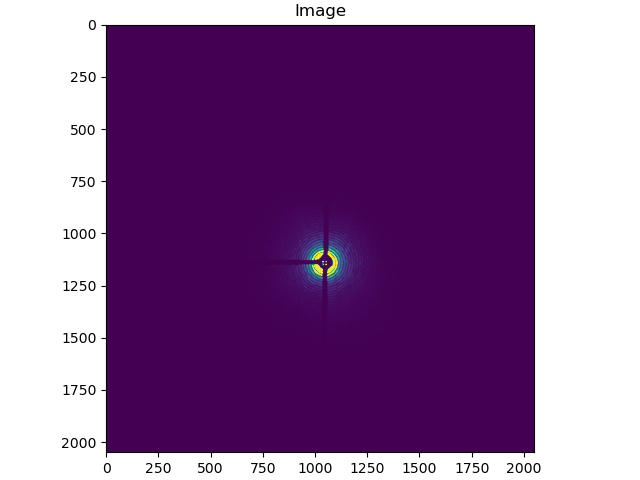

In [16]:
# Load image
image, _ = load_processing(im_id)

# Plot
fig, ax = cimshow(image)
ax.set_title("Image")

## Load topo data set and average

Loaded: /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01407.nxs (2 frames)


interactive(children=(FloatRangeSlider(value=(604.6856781921387, 9384.171909180393), description='contrast', l…

Text(0.5, 1.0, 'Topo')

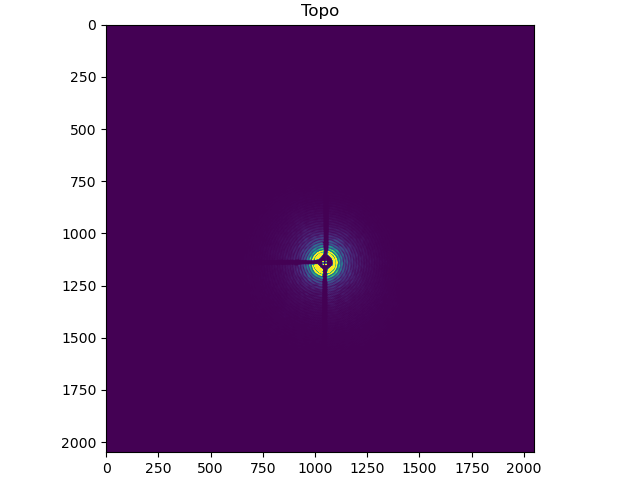

In [17]:
# Load topo
(
    topo,
    _,
) = load_processing(topo_id)

# Plot
fig, ax = cimshow(topo)
ax.set_title("Topo")

# Center holograms

* Find center of the hologram to get a well-defined q-space. 
* Create smooth mask for beamstop or overexposed areas in direct beam

## Basic widget to find center

Try to **align** the circles to the **center of the scattering pattern**. Care! Position of beamstop might be misleading and not represent the actual center of the hologram. 

interactive(children=(FloatRangeSlider(value=(-31.0, 1458.5050000008196), description='contrast', layout=Layou…

interactive(children=(IntText(value=1026, description='c0', step=0), IntText(value=1024, description='c1', ste…

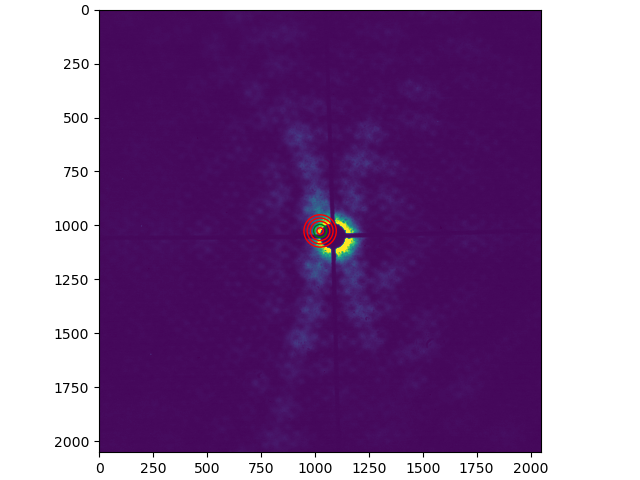

In [ ]:
# Set center position via widget
ic = interactive.InteractiveCenter(image)

In [ ]:
# Get center positions
center = [ic.c0, ic.c1]
print(f"Center:", center)
shift_c = np.array(image.shape) / 2 - center
print(f"Shift vector:", shift_c)

Center: [1053, 1084]
Shift vector: [-27. -60.]


## Azimuthal integrator widget for finetuning
More of an "expert widget" which works very well for alignment if you have an Airy Pattern as a scattering image. PyFai transforms images from carthesian detector coordinate system into polar coordinate system with angle `phi` and radial distance `q` as axis (azimuthal transformation). The center of the coordinate system will be defined in the azimuthal integrator class and must not necessarily represents the center coordinates of your image array. If the center is set correctly, all rings of the Airy pattern will be transformed into a straight line in the I(q,chi)-plot as rings appear at a given q for all angles chi.

In [ ]:
# Setup azimuthal integrator for virtual geometry
ai = AzimuthalIntegrator(
    dist=experimental_setup["ccd_dist"],
    detector=detector,
    wavelength=experimental_setup["lambda"],
    poni1=center[0]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # y (vertical)
    poni2=center[1]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # x (horizontal)
)

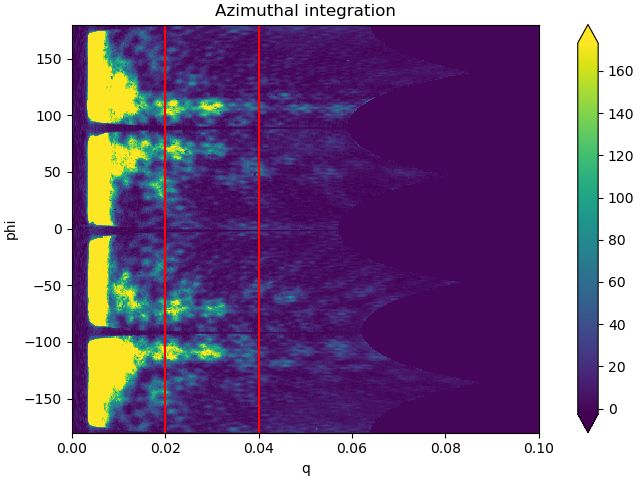

In [ ]:
# Not the widget, just for double checking to find correct radial range for plotting
# Show some vertical lines at these qs
q_lines = [0.02, 0.04]

# Perform azimuthal transformation
I_t, q_t, phi_t = ai.integrate2d(
    image,
    500,  # number of points for phi
    radial_range=(0.01, 0.1),  # relevant q-range
    unit="q_nm^-1",
    correctSolidAngle=False,
)
# Combine in an xarray for plotting
az2d = xr.DataArray(I_t, dims=("phi", "q"), coords={"q": q_t, "phi": phi_t})

# Plot
fig, ax = plt.subplots()
mi, ma = np.percentile(I_t, [1, 95])
az2d.plot.imshow(ax=ax, vmin=mi, vmax=ma)
plt.title(f"Azimuthal integration")

# Add vertical lines to plot
for qt in q_lines:
    ax.axvline(qt, ymin=0, ymax=180, c="red")

Left: 1d azimuthal Integration I(q)
Right: 2d azimuthal Integration I(q,chi)
Use sliders to adjust center position. Try to transform all rings of the Airy pattern into a straight line in the I(q,chi)-plot. Maximize fringe contrast in I(q) plot for fine-tuning.


interactive(children=(FloatSlider(value=1053.0, description='y-center', layout=Layout(width='500px'), max=1368…

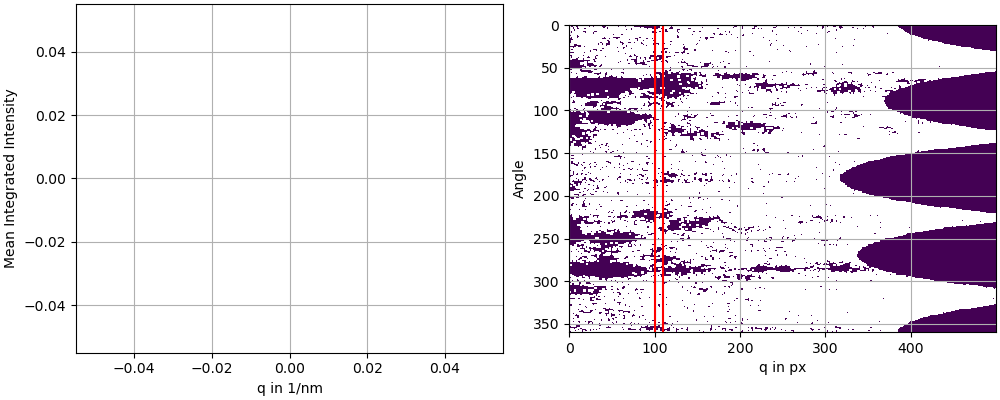

In [ ]:
# The widget
aic = interactive.AzimuthalIntegrationCenter(
    np.log10(image),
    # image,
    ai,
    c0=center[0],
    c1=center[1],
    im_data_range=[1, 95],
    radial_range=(0.025, 0.075),
    qlines=[100, 110],
)

In [23]:
# Get center positions from widget
center = [aic.c0, aic.c1]
print(f"Center:", center)

Center: [1145.0, 1046.0]


## Centering of image hologram

In [ ]:
# Apply to topo and image
shift_c = np.array(image.shape) / 2 - center
im_c = cci.shift_image(image, shift_c)
topo_c = cci.shift_image(topo, shift_c)  # centered image

# Create beamstops

We want to cover the beamstop with a smooth circle to cover its sharp edges as these would create ringing-like artifacts in the reconstruction plane. Make it only as large as necessary to keep as much information as possible.

## Circle beamstop

interactive(children=(FloatRangeSlider(value=(-31.000000000000323, 255.9999999999991), description='contrast',…

interactive(children=(IntText(value=131, description='rBS'), IntText(value=4, description='stdBS'), Output()),…

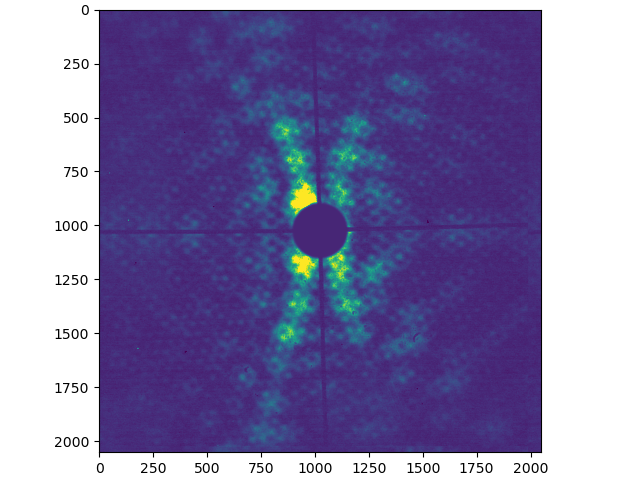

In [ ]:
# Set beamstop diameter and std for smoothing filter.
# Higher values mean stronger smoothing.
# If you have a very small beamstop you might need to reduce the smoothing value.
# Otherwise the beamstop center won't mask the direct beam with zeros
bs = interactive.InteractiveBeamstop(
    im_c, im_c.shape[0] / 2, im_c.shape[1] / 2, rBS=48, stdBS=4
)

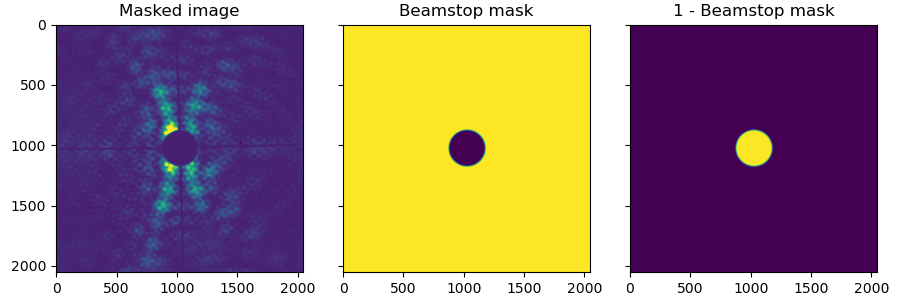

In [ ]:
# Take value from widget and create beamstop mask
bs_diam = bs.rBS
bs_smoothing = bs.stdBS
mask_bs = 1 - cci.circle_mask(
    topo.shape, np.array(topo.shape) / 2, bs.rBS, sigma=bs_smoothing
)

# Apply beamstop to image
im_b = im_c * mask_bs

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(im_b, [0.1, 99.9])
ax[0].imshow(im_b, cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Masked image")

ax[1].imshow(mask_bs)
ax[1].set_title("Beamstop mask")

ax[2].imshow(1 - mask_bs)
ax[2].set_title("1 - Beamstop mask")
plt.tight_layout()

## Manual masking

interactive(children=(FloatRangeSlider(value=(-31.000000000000323, 255.9999999999991), description='contrast',…

Click on the figure to create a polygon corner.
Click `Add mask` to store coordinates and apply mask.
Press the 'esc' key to reset the polygon for new drawing.

Try holding the 'shift' key to move all of the vertices.
Try holding the 'ctrl' key to move a single vertex.
Button `Delete mask` deletes the masks recursively.


Button(button_style='warning', description='Add mask', layout=Layout(height='auto', width='100px'), style=Butt…

Button(description='Delete mask', layout=Layout(height='auto', width='100px'), style=ButtonStyle())

Output()

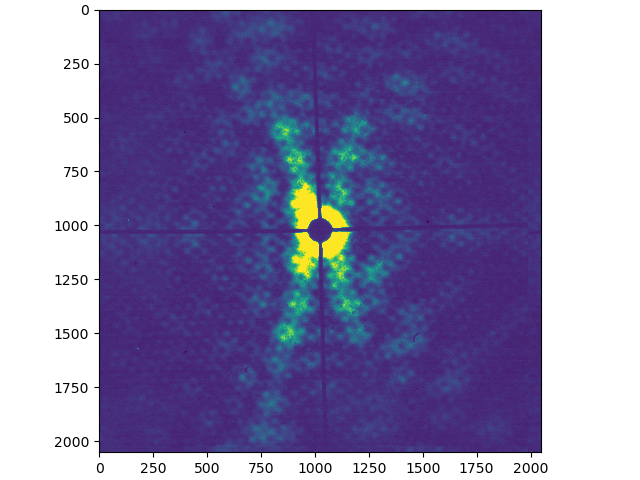

In [ ]:
poly_mask = interactive.draw_polygon_mask(im_c)

Copy these coordinates into the 'load_poly_coordinates()' function:
[]


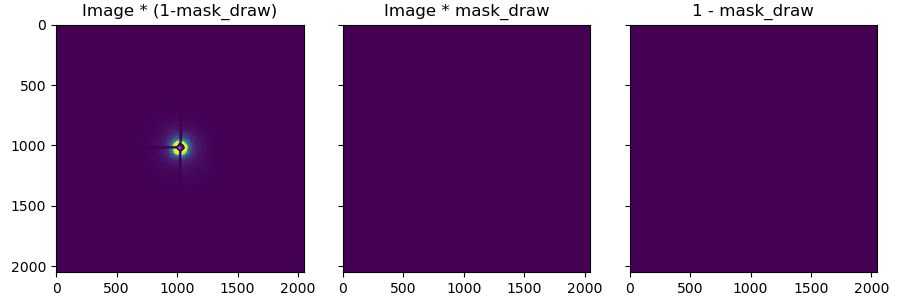

In [28]:
# Take poly coordinates and mask from widget
p_coord = poly_mask.coordinates
mask_draw = poly_mask.full_mask.astype(int)

print("Copy these coordinates into the 'load_poly_coordinates()' function:")
print(p_coord)

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(im_c * (1 - mask_draw), [0.1, 99.9])
ax[0].imshow(im_c * (1 - mask_draw), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask_draw)")

mi, ma = np.percentile(im_c * mask_draw, [0.1, 99.9])
ax[1].imshow(im_c * mask_draw, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask_draw")

ax[2].imshow(1 - mask_draw)
ax[2].set_title("1 - mask_draw")
plt.tight_layout()

In [29]:
def load_poly_coordinates():
    """
    Dictionary that stores polygon corner coordinates of all drawn masks
    """

    # Setup dictonary
    mask_coordinates = dict()

    # Mask #1
    mask_coordinates["bs_left_part"] = [
        [
            (992.6311464773979, 1003.4959894309079),
            (964.5760364341819, 1007.7234717661871),
            (885.7911383676166, 1002.3430397031046),
            (877.7204902729928, 1004.6489391587114),
            (860.4262443559419, 1001.1900899753011),
            (850.5621189069574, 1002.3430397031045),
            (837.4953553251855, 1005.0332557346458),
            (723.3533322726494, 1007.3391551902525),
            (716.4356339058289, 1001.5744065512356),
            (690.3021067422853, 1004.6489391587113),
            (550.6243823109924, 1008.748315968679),
            (502.2004937432498, 1007.5953662408757),
            (352.48783649589046, 1009.6877564876302),
            (352.8721530718249, 1041.9703488661253),
            (531.9636774572857, 1040.4330825623874),
            (651.6544923291508, 1036.965811067514),
            (737.1798834597648, 1035.8100625387221),
            (835.1741779632291, 1033.1953305949457),
            (869.9761790061834, 1034.9888079493066),
            (886.8861083472998, 1040.7535565883236),
            (897.6469724734649, 1035.7574411011756),
            (952.6042428320933, 1031.914275341831),
            (982.5809357549815, 1031.914275341831),
            (999.4908650960979, 1025.380893550945),
        ]
    ]

    # Mask #2
    mask_coordinates["bs_bot_part"] = [
        [
            (1019.2109649908732, 1043.0718589413025),
            (1006.8790517868313, 1044.9216459219085),
            (1011.195221408246, 1077.6012159126199),
            (1006.8790517868313, 1090.5497247768637),
            (1007.4956474470334, 1104.1148293013098),
            (1005.6458604664272, 1126.3122730685852),
            (1006.2624561266292, 1143.576951554244),
            (1007.4956474470333, 1291.5599100027468),
            (1006.4679880133632, 1527.3734947155926),
            (1003.7275628569096, 1782.5755874103486),
            (1033.3241545466103, 1781.6849492345011),
            (1032.090963226206, 1676.247091339943),
            (1032.9130907731424, 1519.905836164256),
            (1036.612664734355, 1449.6139309012171),
            (1036.064579703064, 1216.4722607159133),
            (1034.488835238103, 1119.4612101774505),
            (1036.3386222187094, 1052.252283215422),
        ]
    ]

    # Mask #3
    mask_coordinates["bs_top_part"] = [
        [
            (1036.7151195919967, 981.0594500779512),
            (1046.4571003892586, 940.1790942026023),
            (1043.6736773043267, 737.6850647737999),
            (1041.6634272985425, 638.3323241033106),
            (1043.0551388410086, 508.20729488274003),
            (1042.59123499352, 433.75072736080926),
            (1011.973581059268, 435.14243890327526),
            (1011.2777252880351, 623.0234971361847),
            (1011.3550425959497, 722.2989204987591),
            (1011.3550425959497, 766.833689857671),
            (1010.6591868247168, 786.3176514521949),
            (1013.4426099096488, 814.8477380727478),
            (1012.0508983671828, 855.9032285754947),
            (1012.5148022146715, 912.1902287374529),
            (1007.6438118160405, 926.8031999333458),
            (1012.5148022146715, 933.0659018744428),
            (1012.5148022146715, 951.8540076977338),
            (1012.5148022146715, 981.5131039196557),
        ]
    ]

    return mask_coordinates

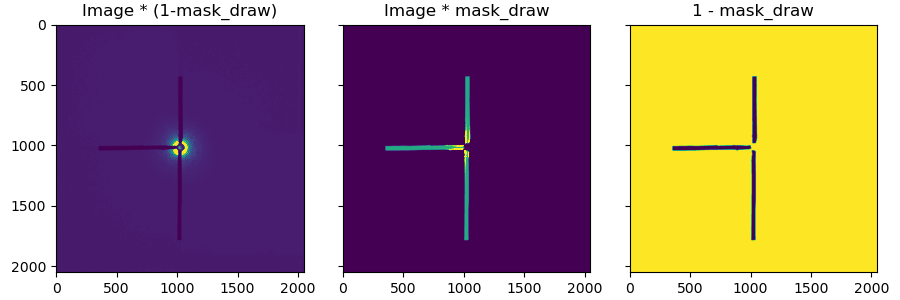

In [30]:
# Which drawn masks do you want to load?
polygon_names = ["bs_left_part", "bs_bot_part", "bs_top_part"]
mask_draw = load_poly_masks(
    polygon_names,
)

# Expand Mask if necessary
footprint = skimage.morphology.disk(2)
mask_draw = skimage.morphology.dilation(mask_draw, footprint)

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(im_c * (1 - mask_draw), [0.1, 99.9])
ax[0].imshow(im_c * (1 - mask_draw), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask_draw)")

mi, ma = np.percentile(im_c * mask_draw, [0.1, 99.9])
ax[1].imshow(im_c * mask_draw, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask_draw")

ax[2].imshow(1 - mask_draw)
ax[2].set_title("1 - mask_draw")
plt.tight_layout()

## Automated Beamstop detection

interactive(children=(FloatRangeSlider(value=(-31.000000000000323, 255.9999999999991), description='contrast',…

interactive(children=(FloatSlider(value=30.0, description='Filter Threshold', max=5000.0, step=10.0), Output()…

interactive(children=(FloatSlider(value=250.0, description='Radius', max=1026.0, step=10.0), Output()), _dom_c…

interactive(children=(FloatSlider(value=8.0, description='Expansion', max=20.0, step=1.0), Output()), _dom_cla…

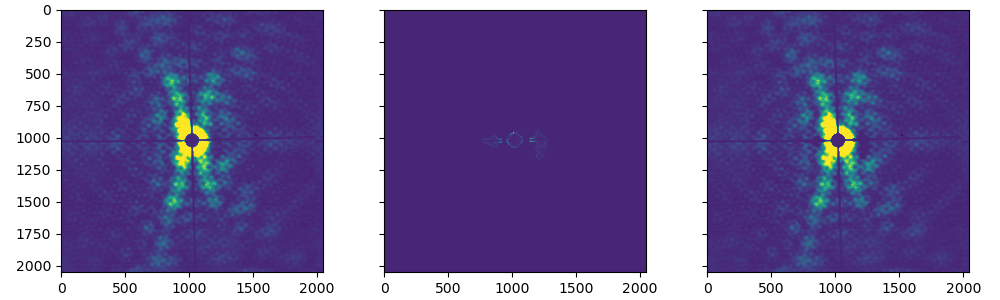

In [ ]:
# Initial parameter for automatic beamstop detection
thres = 30
radi_thres = 250
expand = 8
method_bs = "gradient"
auto_bs = interactive.InteractiveAutoBeamstop(
    im_c, thres, radi_thres, expand, method=method_bs
)

## Combine all beamstops

Text(0.5, 1.0, 'Image-Topo')

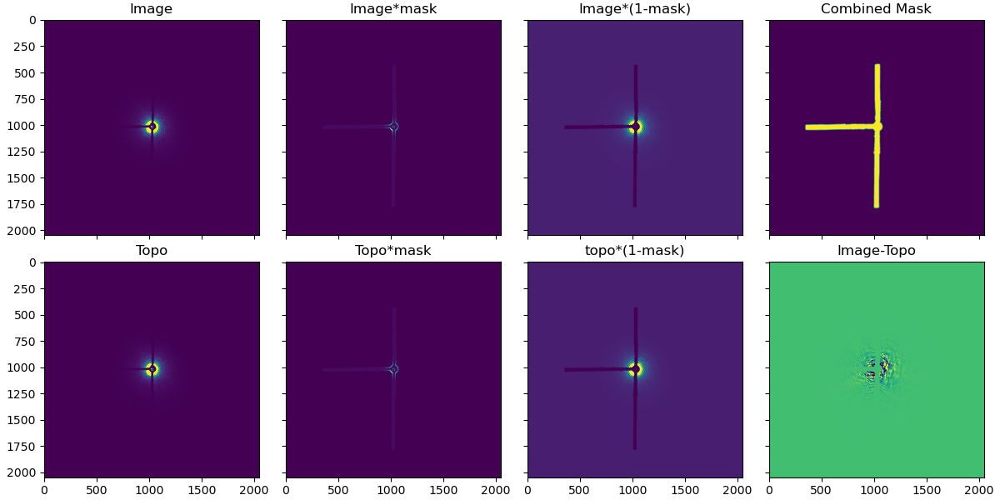

In [32]:
# Use automatically determined beamstop mask?
use_bs_auto = True

# Use otsu center?
use_otsu = True

# Use drawn beamstop?
use_draw = True

# Load auto beamstop
if use_bs_auto is True:
    mask_im = automated_beamstop(
        im_c, auto_bs.thres, auto_bs.radius, auto_bs.expand, method=method_bs
    )
    mask_topo = automated_beamstop(
        topo_c, auto_bs.thres, auto_bs.radius, auto_bs.expand, method=method_bs
    )
elif use_bs_auto is False:
    mask_im = mask_draw.copy()
    mask_topo = mask_draw.copy()

# Load beamstop center
if use_otsu is True:
    tmp = cci.circle_mask(topo.shape, np.array(topo.shape) / 2, 90, sigma=None)
    mask_im = (1 - tmp) * mask_im + tmp * automated_beamstop_center(im_c, 8)
    mask_topo = (1 - tmp) * mask_topo + tmp * automated_beamstop_center(topo_c, 8)
elif use_otsu is False:
    mask_bs_center = cci.circle_mask(
        topo.shape, np.array(topo.shape) / 2, bs.rBS + bs.stdBS, sigma=None
    )
    mask_im = mask_im + mask_bs_center
    mask_topo = mask_topo + mask_bs_center

# Load drawn beamstop
if use_draw is True:
    tmp = cci.circle_mask(
        topo.shape, np.array(topo.shape) / 2, auto_bs.radius, sigma=None
    )
    mask_im = tmp * mask_im + (1 - tmp) * mask_draw
    mask_topo = tmp * mask_topo + (1 - tmp) * mask_draw

# Create image specific beamstop mask
mask_im = mask_im + (im_c > 65000)
mask_im[mask_im > 1] = 1

# Create topo specific beamstop mask
mask_topo = mask_topo + (topo_c > 65000)
mask_topo[mask_topo > 1] = 1

# Combine both
mask_pixel = mask_im + mask_topo
mask_pixel[mask_pixel > 1] = 1

# Sharp and smooth mask
footprint = skimage.morphology.disk(2 * 4)
mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, 2)

# Plot both
fig, ax = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True)
mi, ma = np.percentile(im_c, [1, 99.9])
ax[0, 0].imshow(im_c, vmin=mi, vmax=ma)
ax[0, 0].set_title("Image")
mi, ma = np.percentile(im_c * mask_im, [1, 99.99])
ax[0, 1].imshow(im_c * mask_im, vmin=mi, vmax=ma)
ax[0, 1].set_title("Image*mask")
mi, ma = np.percentile(im_c * (1 - mask_im), [0.1, 99.9])
ax[0, 2].imshow(im_c * (1 - mask_im), vmin=mi, vmax=ma)
ax[0, 2].set_title("Image*(1-mask)")
ax[0, 3].imshow(mask_pixel_smooth)
ax[0, 3].set_title("Combined Mask")

mi, ma = np.percentile(topo_c, [1, 99.9])
ax[1, 0].imshow(topo_c, vmin=mi, vmax=ma)
ax[1, 0].set_title("Topo")
mi, ma = np.percentile(topo_c * mask_im, [1, 99.99])
ax[1, 1].imshow(topo_c * mask_topo, vmin=mi, vmax=ma)
ax[1, 1].set_title("Topo*mask")
mi, ma = np.percentile(topo_c * (1 - mask_topo), [0.1, 99.9])
ax[1, 2].imshow(topo_c * (1 - mask_topo), vmin=mi, vmax=ma)
ax[1, 2].set_title("topo*(1-mask)")
mi, ma = np.percentile((im_c - topo_c) * (1 - mask_pixel_smooth), [0.1, 99.9])
ax[1, 3].imshow((im_c - topo_c) * (1 - mask_pixel_smooth), vmin=mi, vmax=ma)
ax[1, 3].set_title("Image-Topo")

# Image Registration

Relative drift between data holograms and their corresponding topo holograms is calculated by image registration algorithm. Necessary to get well defined difference hologram. The reference is always the static background image (topo).

## Set Alignment ROI 

Set a region of interest (ROI) of reference (topo) use for image registration is performed. Don't select ROI which contains the beamstop as this leads to wrong results

How to use:
1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

In [ ]:
fig, ax = cimshow(im_c * (1 - mask_im))
ax.set_title("Can include beamstop")

NameError: name 'mask_im' is not defined

In [42]:
# Takes start and end of x and y axis
x1, x2 = ax.get_xlim()
y2, y1 = ax.get_ylim()
roi_im_reg = np.array([y1, y2, x1, x2]).astype(int)

roi_im_reg = [767, 1239, 1092, 1460]  # other sample
roi_im_reg = np.s_[roi_im_reg[0] : roi_im_reg[1], roi_im_reg[2] : roi_im_reg[3]]

print(f"Image registration roi:", roi_im_reg)

Image registration roi: (slice(767, 1239, None), slice(1092, 1460, None))


## Calculate drift of images

In [43]:
shift = cci.image_registration(
    im_c[roi_im_reg],
    topo_c[roi_im_reg],
    method="dipy",
    static_mask=mask_pixel[roi_im_reg],
    moving_mask=mask_pixel[roi_im_reg],
)
print(shift)

Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
[-0.   -0.04]


In [44]:
# shift = [0, 0]

## Center and apply circular beamstop to topo image

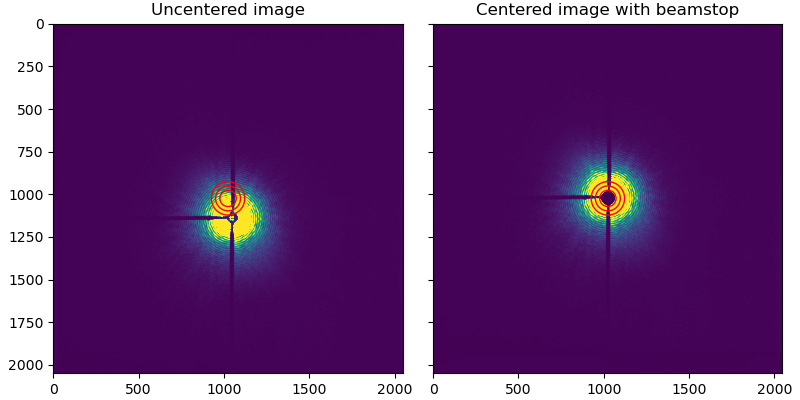

In [45]:
# Shift and apply beamstop
topo_c = cci.shift_image(topo, shift_c + shift)  # centered image
topo_b = topo_c * mask_bs  # centered image with beamstop

# Plot original and shifted holos
mi, ma = np.percentile(np.real(im_c[im_c != 0]), (0.1, 99))
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
ax[0].imshow(np.real(image), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Uncentered image")
ax[1].imshow(np.real(im_b), cmap="viridis", vmin=mi, vmax=ma)
ax[1].set_title("Centered image with beamstop")
plt.tight_layout()

# Add circles with different radi r
tmp = np.array(image.shape) / 2
for r in np.arange(bs_diam, 100, 25):
    ax[0].add_artist(plt.Circle((tmp[1], tmp[0]), r, fill=None, ec="red"))
    ax[1].add_artist(plt.Circle((tmp[1], tmp[0]), r, fill=None, ec="red"))

# Calculate difference holograms

You can see the reconstrution of the magnetization only after subtracting the large background that you get from the diffraction on the circular object aperture (Airy Pattern). This might require a scaling factor to correct intensity changes between the hologram and the topo. Scaling factor will be determined automatically by a linear fit. If the fit seems off, there might be an issue with the data

Linear Fit: 0.9421*x + 36.0269


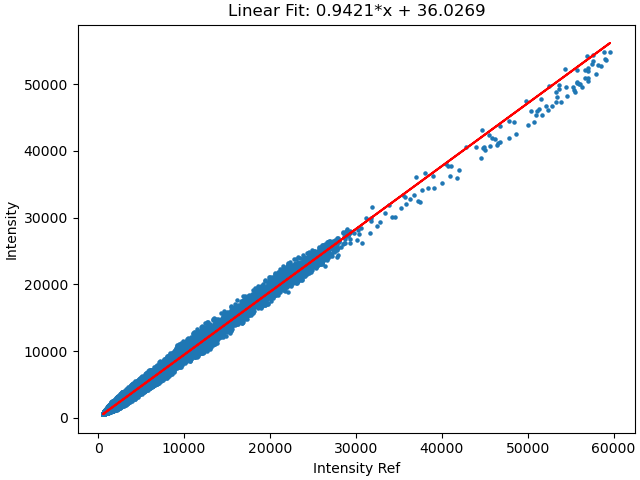

In [46]:
# Get scaling factor and offset
factor, offset = cci.dyn_factor(
    im_c * (1 - mask_pixel_sharp),
    topo_c * (1 - mask_pixel_sharp),
    method="correlation",
    print_out=True,
    plot=True,
)

# Calculate differences (magnetic) and sums (topographc) contrast holograms.
# _c: centered, without beamstop, _b: centered, with beamstop
diff_c = im_c / factor - topo_c - offset
diff_b = im_b / factor - topo_b - offset
sum_c = im_c / factor + topo_c - offset
sum_b = im_b / factor + topo_b - offset

interactive(children=(FloatRangeSlider(value=(-324.8100332040777, 374.8367678012786), description='contrast', …

Text(0.5, 1.0, ' Diff Id 1409')

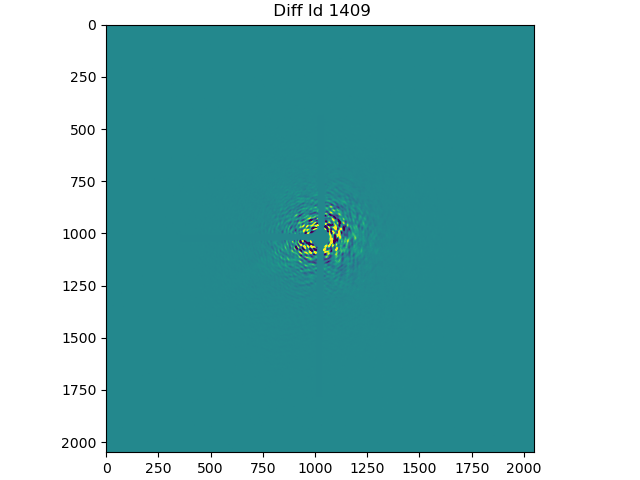

In [47]:
# Plot an example of the difference or sum hologram
fig, ax = cimshow(diff_b * (1 - mask_pixel))
ax.set_title(f" Diff Id %d" % im_id)

# fig, ax = cimshow(sum_b)
# ax.set_title(f" Sum Id %d" % im_id)

# Reconstruct Diff Holos (FTH)

Reconstruct the hologramm.
1. Chose a region of interest (ROI) which means selecting one reconstruction from the rconstruction plane.
2. Propagate the image and shift the phase for maximal contrast and sharpness in your ROI
3. Optional finetuning with a widget

## Set Patterson Map ROI

Choose the reconstructions as the ROI.

1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

interactive(children=(FloatRangeSlider(value=(-0.02774430836745642, 0.027598393224834476), description='contra…

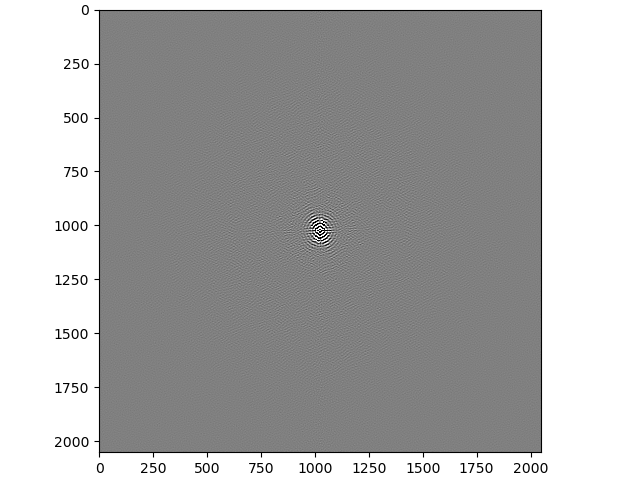

In [ ]:
# Choose contrast mode
# diff_b: magnetic contrast only
tmp = np.real(cci.reconstruct(diff_b * (1 - mask_pixel_smooth)))

# sum_b: topographic contrast only
# tmp = np.real(cci.reconstruct(sum_b * (1 - mask_pixel_smooth)))
fig, ax = cimshow(tmp, cmap="gray")

In [55]:
# Execute to get roi
x1, x2 = ax.get_xlim()
y2, y1 = ax.get_ylim()
roi = np.array([y1, y2, x1, x2]).astype(int)  # ystart, ystop, xstart, xstop
roi = [623, 816, 703, 894]
roi_s = np.s_[roi[0] : roi[1], roi[2] : roi[3]]
print(f"Roi Reco:{roi}")

Roi Reco:[623, 816, 703, 894]


## Tune propagation and phase
Focus the image by tuning the propagation distance. This really works like focussing in a microscope.
Phase slider will move contrast between real and imaginary part. Usually we use the phase which maximizes the contrast in the real part

interactive(children=(FloatSlider(value=0.0, description='propagation[um]', layout=Layout(width='90%'), max=10…

Button(description='Finished', style=ButtonStyle())

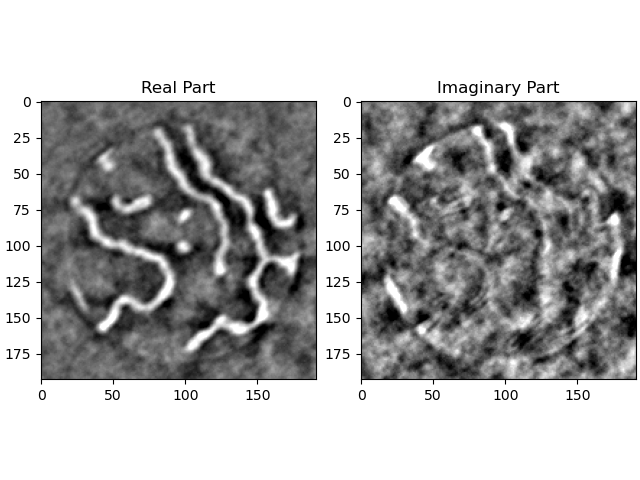

In [56]:
# Widget
slider_prop, slider_phase, button = reco.propagate(
    diff_b * (1 - mask_pixel),
    roi_s,
    experimental_setup=experimental_setup,
    scale=(1, 99),
)

In [57]:
# Read prop dist and phase from widget
prop_dist = slider_prop.value
phase = slider_phase.value

print(f"Propagation distance: %0.2f" % prop_dist)
print(f"Phase: %0.2f" % phase)

Propagation distance: 0.00
Phase: -0.21


## Ugly Widget for finetuning of shift and factor
You can try to find a better scaling factor and optimize the relative shift between image and topo hologram with this widget. Just execute, find your values and then execute next cell to update the values. 

interactive(children=(FloatSlider(value=1145.0, description='centery', max=1155.0, min=1135.0, step=0.5), Floa…

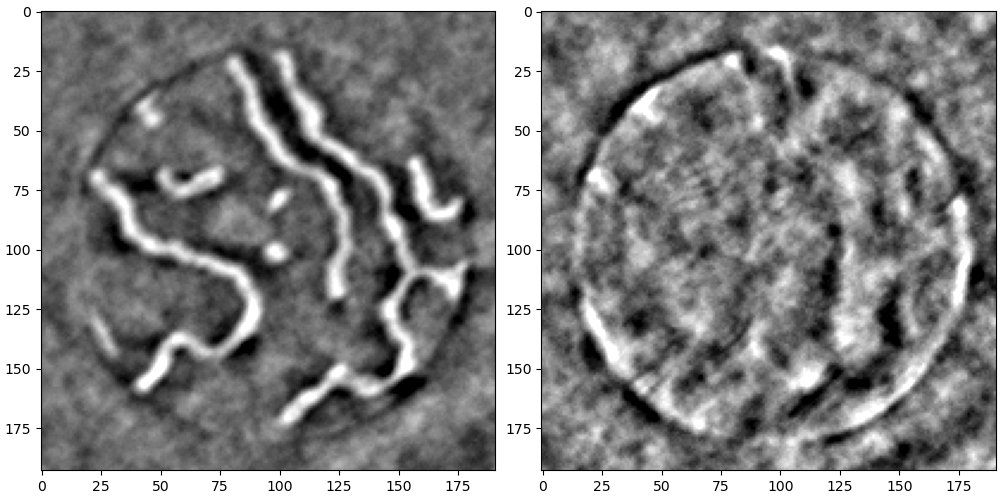

In [59]:
# Ta-ke initial values
temp_factor = factor
temp_shift = shift.copy()
temp_phase = phase

# Open figure
fig, [ax, ax2] = plt.subplots(1, 2, figsize=(10, 5))
fig.tight_layout()

# Widget
layout = ipywidgets.Layout(width="100%")
opts = dict(layout=layout)


@ipywidgets.interact(
    centery=(center[0] - 10, center[0] + 10, 0.5),
    centerx=(center[1] - 10, center[1] + 10, 0.5),
    tfactor=(
        0.6,
        1.4,
        0.0025,
    ),
    xshift=(-4, 4, 0.01),
    yshift=(-4, 4, 0.01),
    tphase=(-2 * np.pi, 2 * np.pi, 0.05),
    options=opts,
)
def update(
    centery=center[0],
    centerx=center[1],
    tfactor=factor,
    yshift=shift[0],
    xshift=shift[1],
    tphase=phase,
):  # initial values
    global temp_shift, temp_factor, temp_center, temp_diff, temp_sum, temp_phase  # ugly writing as global variable

    # Couple widget only and global variables
    temp_shift = [yshift, xshift]
    temp_factor = tfactor
    temp_center = [centery, centerx]
    temp_phase = tphase

    # Calc diff and sum holo
    shifted = cci.shift_image(im_c, temp_shift)
    temp_diff = shifted - temp_factor * topo_c
    temp_sum = shifted + temp_factor * topo_c

    temp_diff = cci.shift_image(temp_diff, [centery - center[0], centerx - center[1]])
    temp_sum = cci.shift_image(temp_sum, [centery - center[0], centerx - center[1]])

    temp_diff = temp_diff * mask_bs * (1 - mask_pixel_smooth)

    # Reconstruction
    recon = cci.reconstruct(
        fth.propagate(
            temp_diff,
            prop_dist * 1e-6,
            experimental_setup=experimental_setup,
        )
        * np.exp(1j * temp_phase)
    )[roi_s]

    # Plots
    vmin, vmax = np.percentile(np.real(recon), (1, 99))
    ax.imshow(np.real(recon), vmin=vmin, vmax=vmax, cmap="gray")
    vmin, vmax = np.percentile(np.imag(recon), (1, 99))
    ax2.imshow(np.imag(recon), vmin=vmin, vmax=vmax, cmap="gray")
    # vmin, vmax = np.percentile(temp_diff * mask_bs * (1 - mask_pixel), (0.1, 99.9))
    # ax2.imshow(temp_diff * mask_bs, vmin=vmin, vmax=vmax)

In [181]:
# Copy values from widget
factor = temp_factor
shift = temp_shift
phase = temp_phase
center = temp_center.copy()
diff_c = temp_diff.copy()
sum_c = temp_sum.copy()
diff_b = diff_c * mask_bs
sum_b = sum_c * mask_bs

## Save reconstruction

Save png files of the images and a h5 file for all important variables

Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Recon_ImId_1409_RefId_1407_cklose_diff.png
Now Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Logs/Data_ImId_1409_RefId_1407_cklose


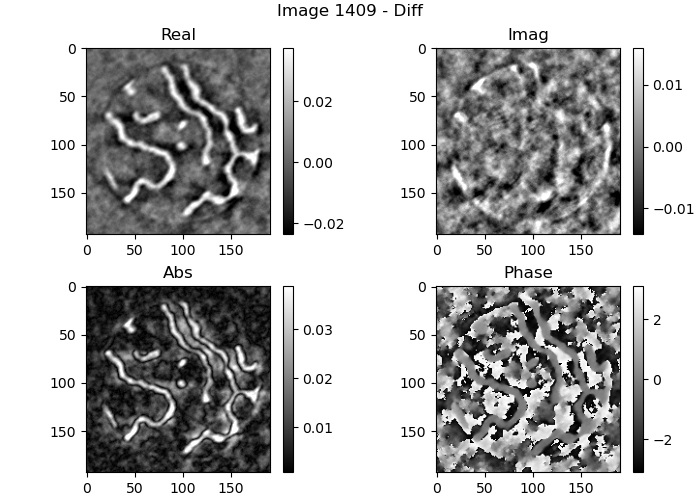

In [60]:
# Setup variable
holo = diff_b * (1 - mask_pixel)
recon = np.zeros(image.shape, dtype=np.complex_)

# Reconstruct
recon = fth.reconstruct(
    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
    * np.exp(1j * phase)
)

# Plot
fig, ax = plt.subplots(2, 2, figsize=(7, 5))
fig.suptitle("Image %d - Diff" % im_id)

# Real
vmin, vmax = np.percentile(np.real(recon[roi_s]), (1, 99))
t_im1 = ax[0, 0].imshow(np.real(recon[roi_s]), vmin=vmin, vmax=vmax, cmap="gray")
ax[0, 0].set_title("Real")
plt.colorbar(t_im1, ax=ax[0, 0])

# Imag
vmin, vmax = np.percentile(np.imag(recon[roi_s]), (1, 99))
t_im2 = ax[0, 1].imshow(np.imag(recon[roi_s]), vmin=vmin, vmax=vmax, cmap="gray")
ax[0, 1].set_title("Imag")
plt.colorbar(t_im2, ax=ax[0, 1])

# Abs
vmin, vmax = np.percentile(np.abs(recon[roi_s]), (1, 99))
t_im3 = ax[1, 0].imshow(np.abs(recon[roi_s]), vmin=vmin, vmax=vmax, cmap="gray")
ax[1, 0].set_title("Abs")
plt.colorbar(t_im3, ax=ax[1, 0])

# Angle
vmin, vmax = np.percentile(np.angle(recon[roi_s]), (1, 99))
t_im4 = ax[1, 1].imshow(np.angle(recon[roi_s]), vmin=vmin, vmax=vmax, cmap="gray")
ax[1, 1].set_title("Phase")
plt.colorbar(t_im4, ax=ax[1, 1])

# Save images
fname = join(
    folder_general, "Recon_ImId_%04d_RefId_%04d_%s_diff.png" % (im_id, topo_id, USER)
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

# Save hdf5 file
save_fth_h5()

Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Recon_ImId_1409_RefId_1407_cklose_diff_small.png


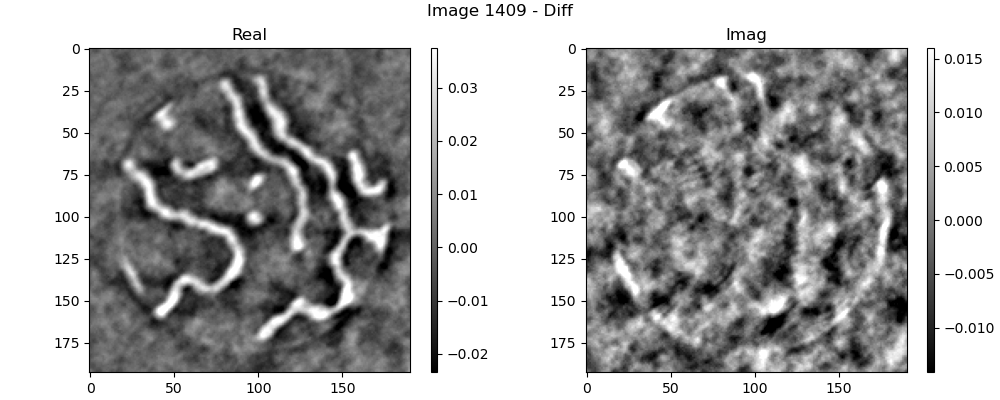

In [61]:
# Saves only real and imaginary part
holo = diff_b * (1 - mask_pixel)
recon = np.zeros(image.shape, dtype=np.complex_)

# Reconstruct
recon = fth.reconstruct(
    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
    * np.exp(1j * phase)
)

# Plot
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle("Image %d - Diff" % im_id)

vmin, vmax = np.percentile(np.real(recon[roi_s]), (1, 99))
t_im1 = ax[0].imshow(np.real(recon[roi_s]), vmin=vmin, vmax=vmax, cmap="gray")
ax[0].set_title("Real")
plt.colorbar(t_im1, ax=ax[0], aspect=50)

vmin, vmax = np.percentile(np.imag(recon[roi_s]), (1, 99))
t_im2 = ax[1].imshow(np.imag(recon[roi_s]), vmin=vmin, vmax=vmax, cmap="gray")
ax[1].set_title("Imag")
plt.colorbar(t_im2, ax=ax[1], aspect=50)

# Save images
fname = join(
    folder_general,
    "Recon_ImId_%04d_RefId_%04d_%s_diff_small.png" % (im_id, topo_id, USER),
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

In [62]:
# Closes all existing plots
plt.close("all")

# CDI Reconstruction

## Create set of pos and neg helicity holograms

In [63]:
# Copy values from FTH reco
pos = sum_c + diff_c
neg = sum_c - diff_c

## Create hologram mask for phase retrieval
``mask_pixel[px,px] == 1`` means invalid, i.e., will be replaced by phase retrieval

interactive(children=(FloatRangeSlider(value=(1211.7087125522298, 2830.238735456107), description='contrast', …

interactive(children=(FloatSlider(value=70.0, description='Filter Threshold', max=5000.0, step=10.0), Output()…

interactive(children=(FloatSlider(value=270.0, description='Radius', max=1024.0, step=10.0), Output()), _dom_c…

interactive(children=(FloatSlider(value=9.0, description='Expansion', max=20.0, step=1.0), Output()), _dom_cla…

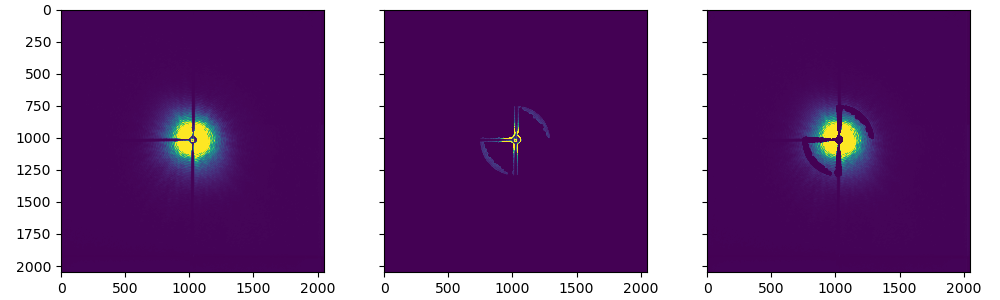

In [64]:
# Initial parameter for automatic beamstop detection
thres = 70
radi = 270
expand = 9
auto_bs = interactive.InteractiveAutoBeamstop(
    pos, thres, radi, expand, method=method_bs
)

Text(0.5, 1.0, 'Image-Topo')

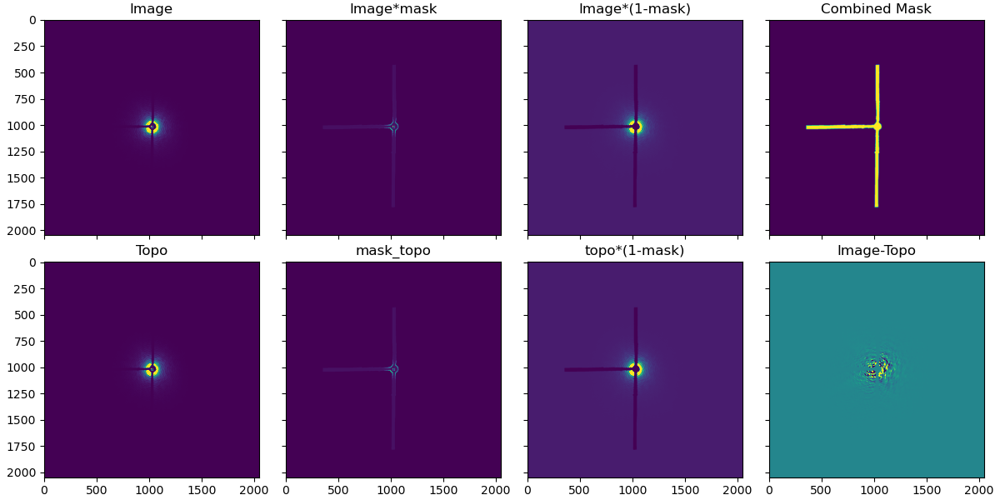

In [70]:
# Use automatically determined beamstop mask?
use_bs_auto = True

# Use otsu center?
use_otsu = True

# Use drawn beamstop?
use_draw = True

# Load auto beamstop
if use_bs_auto is True:
    mask_im = automated_beamstop(
        pos, auto_bs.thres, auto_bs.radius, auto_bs.expand, method=method_bs
    )
    mask_topo = automated_beamstop(
        neg, auto_bs.thres, auto_bs.radius, auto_bs.expand, method=method_bs
    )
elif use_bs_auto is False:
    mask_im = mask_draw.copy()
    mask_topo = mask_draw.copy()

# Load beamstop center
if use_otsu is True:
    tmp = cci.circle_mask(topo.shape, np.array(topo.shape) / 2, 90, sigma=None)
    mask_im = (1 - tmp) * mask_im + tmp * automated_beamstop_center(pos, 7)
    mask_topo = (1 - tmp) * mask_topo + tmp * automated_beamstop_center(neg, 7)
elif use_otsu is False:
    mask_bs_center = cci.circle_mask(
        topo.shape, np.array(topo.shape) / 2, bs.rBS + bs.stdBS, sigma=None
    )
    mask_im = mask_im + mask_bs_center
    mask_topo = mask_topo + mask_bs_center

# Load drawn beamstop
if use_draw is True:
    tmp = cci.circle_mask(
        topo.shape, np.array(topo.shape) / 2, auto_bs.radius, sigma=None
    )
    mask_im = tmp * mask_im + (1 - tmp) * mask_draw
    mask_topo = tmp * mask_topo + (1 - tmp) * mask_draw

# Create image specific beamstop mask
mask_im = mask_im + (pos > 2 * 65000)
mask_im[mask_im > 1] = 1

# Create topo specific beamstop mask
mask_topo = mask_topo + (neg > 2 * 65000)
mask_topo[mask_topo > 1] = 1

# Combine both
mask_pixel = mask_im + mask_topo
mask_pixel[mask_pixel > 1] = 1

# Expand mask
footprint = skimage.morphology.disk(2 * 4)
mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, 4)

# Plot both
fig, ax = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True)
mi, ma = np.percentile(pos, [1, 99.9])
ax[0, 0].imshow(pos, vmin=mi, vmax=ma)
ax[0, 0].set_title("Image")
mi, ma = np.percentile(pos * mask_im, [0.1, 99.99])
ax[0, 1].imshow(pos * mask_im, vmin=mi, vmax=ma)
ax[0, 1].set_title("Image*mask")
mi, ma = np.percentile(pos * (1 - mask_im), [0.1, 99.9])
ax[0, 2].imshow(pos * (1 - mask_im), vmin=mi, vmax=ma)
ax[0, 2].set_title("Image*(1-mask)")
ax[0, 3].imshow(mask_pixel)
ax[0, 3].set_title("Combined Mask")

mi, ma = np.percentile(neg, [1, 99.9])
ax[1, 0].imshow(neg, vmin=mi, vmax=ma)
ax[1, 0].set_title("Topo")
mi, ma = np.percentile(neg * mask_topo, [0.1, 99.99])
ax[1, 1].imshow(neg * mask_topo, vmin=mi, vmax=ma)
ax[1, 1].set_title("mask_topo")
mi, ma = np.percentile(neg * (1 - mask_topo), [0.1, 99.9])
ax[1, 2].imshow(neg * (1 - mask_topo), vmin=mi, vmax=ma)
ax[1, 2].set_title("topo*(1-mask)")
mi, ma = np.percentile((pos - neg) * (1 - mask_pixel), [0.1, 99.9])
ax[1, 3].imshow((pos - neg) * (1 - mask_pixel), vmin=mi, vmax=ma)
ax[1, 3].set_title("Image-Topo")

## Draw support mask

## Execute if you want to create a new support mask

In [71]:
# How many references do you have?
nr_ref = 5

# Setup coordinates (nr_ref + 1 coordinates, as there is always the object aperture)
support_coordinates = [
    [pos.shape[-2] // 2, pos.shape[-1] // 2, 7] for k in range(nr_ref + 1)
]

## Execute if you want to load an existing support mask

In [73]:
def get_supportmask_coordinates(sample):
    """
    Dictionary that stores coordinates of circular support mask apertures
    """

    # Setup dictonary
    support_coord = dict()

    # coordinates
    support_coord["s2306a-C1"] = [
        [721.0, 800.0, 86.0],
        [346.5, 793.5, 6.5],
        [601.0, 1155.0, 8.0],
        [612.0, 440.5, 7.5],
        [1030.5, 582.5, 6.5],
        [1024.5, 1024.5, 6.5],
    ]

    support_coord["s2308a-B1"] = [
        [957.0, 894.5, 30.0],
        [917.5, 849.0, 4.5],
        [885.0, 869.0, 5.0],
        [905.0, 895.0, 5.0],
        [885.5, 921.5, 4.5],
        [893.5, 1025.0, 4.5],
        [956.5, 1105.0, 4.5],
        [1010.0, 874.5, 5.5],
        [1010.5, 913.5, 5.0],
        [1024.0, 1024.0, 4.5],
    ]

    return support_coord[sample]

Text(0.5, 1.0, 'Image with overlayed mask')

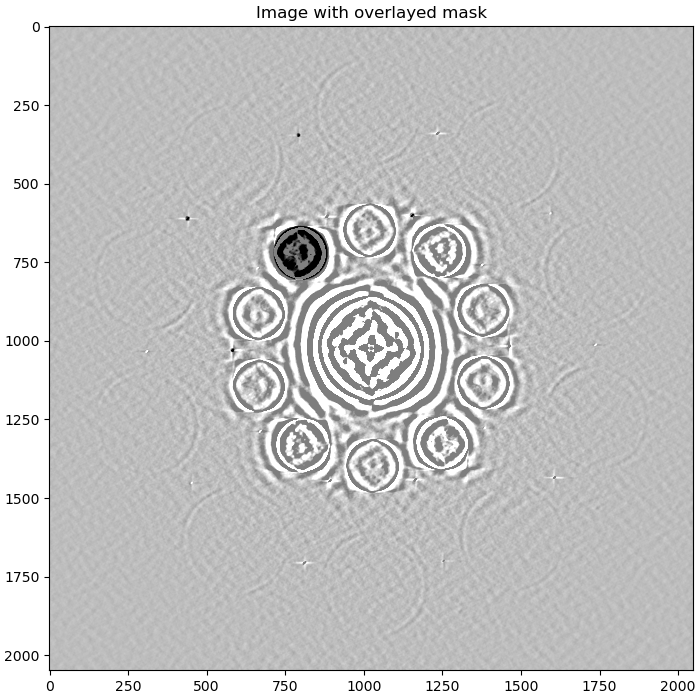

In [74]:
# Which sample do you study? ("GdFe", "Permalloy", "YIG")
sample = "s2306a-C1"

# Get coordinates and create supportmask
support_coordinates = get_supportmask_coordinates(sample)
supportmask = create_supportmask(support_coordinates, pos.shape)

# Plot
fig, ax = plt.subplots(figsize=(7, 7))
mi, ma = np.percentile(np.real(fth.reconstruct(pos * (1 - mask_pixel_smooth))), (5, 95))
ax.imshow(
    np.real(fth.reconstruct(pos * (1 - mask_pixel_smooth))),
    vmin=mi,
    vmax=ma,
    cmap="gray",
)
ax.imshow(supportmask, alpha=0.5, cmap="binary")
ax.set_title("Image with overlayed mask")

### Create new support mask

In [75]:
# Get coordinates and cre_ate supportmask
support_coordinates = get_supportmask_coordinates(sample)

interactive(children=(FloatRangeSlider(value=(-0.1410514385278207, 0.1407235946400496), description='contrast'…

interactive(children=(IntSlider(value=0, description='circle index', layout=Layout(width='250px'), max=5), Out…

interactive(children=(FloatSlider(value=721.0, description='yc', layout=Layout(width='600px'), max=2048.0, ste…

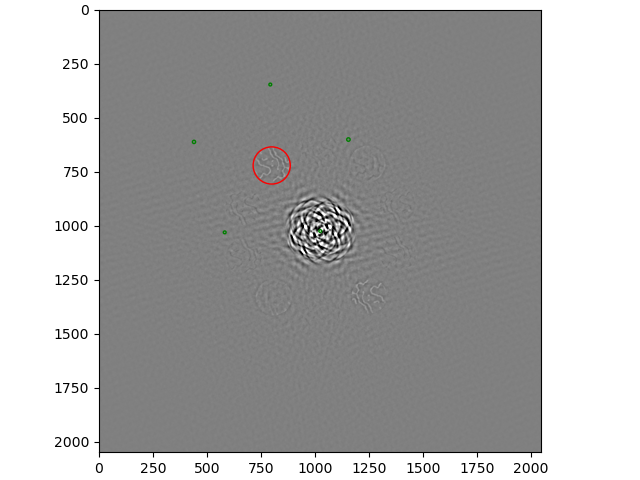

In [76]:
# Widget to find the positions and sizes of the different apertures
ds = interactive.InteractiveCircleCoordinates(
    np.real(fth.reconstruct(diff_b * mask_bs * np.exp(1j * phase) * (1 - mask_pixel))),
    len(support_coordinates),
    support_coordinates=support_coordinates.copy(),
)

Text(0.5, 1.0, 'Image with overlayed mask')

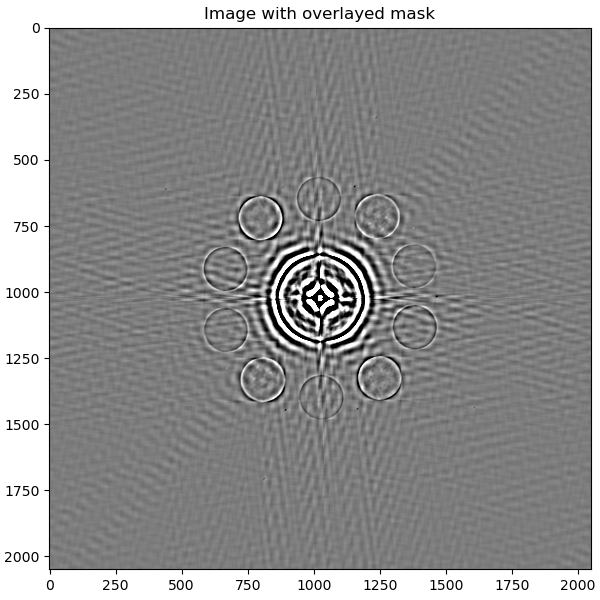

In [77]:
# Take coordinates of circles from widget
support_coordinates = ds.c_yxr

# Create supportmask
supportmask = create_supportmask(support_coordinates, pos.shape)

# Plot supportmask
fig, ax = plt.subplots(figsize=(6, 6))
mi, ma = np.percentile(
    np.real(fth.reconstruct(pos * mask_bs * np.exp(1j * phase) * (1 - mask_pixel))),
    (1, 99),
)
ax.imshow(supportmask, alpha=0.3, cmap="binary")
ax.imshow(
    np.real(fth.reconstruct(pos * mask_bs * np.exp(1j * phase) * (1 - mask_pixel))),
    vmin=mi,
    vmax=ma,
    cmap="gray",
)
ax.set_title("Image with overlayed mask")

### Take Roi

In [81]:
roi_cdi = interactive.axis_to_roi(ax)
roi_cdi = [627, 818, 707, 892]
roi_cdi = np.s_[roi_cdi[0] : roi_cdi[1], roi_cdi[2] : roi_cdi[3]]
print("Sliced roi:", roi_cdi)

Sliced roi: (slice(627, 818, None), slice(707, 892, None))


## Do Phase Retrieval

In [100]:
(
    retrieved_p,
    retrieved_n,
    retrieved_p_pc,
    retrieved_n_pc,
    bsmask_p,
    bsmask_n,
) = phase_retrieval(pos, neg, mask_pixel, supportmask, Startimage=None, Startgamma=None)

CDI - larger mask
############ -   CDI
--- 4.25 seconds ---
############   -   CDI_pc
--- 11.7 seconds ---
Phase Retrieval Done!


## Reconstruct images

interactive(children=(FloatSlider(value=0.0, description='propagation[um]', layout=Layout(width='90%'), max=10…

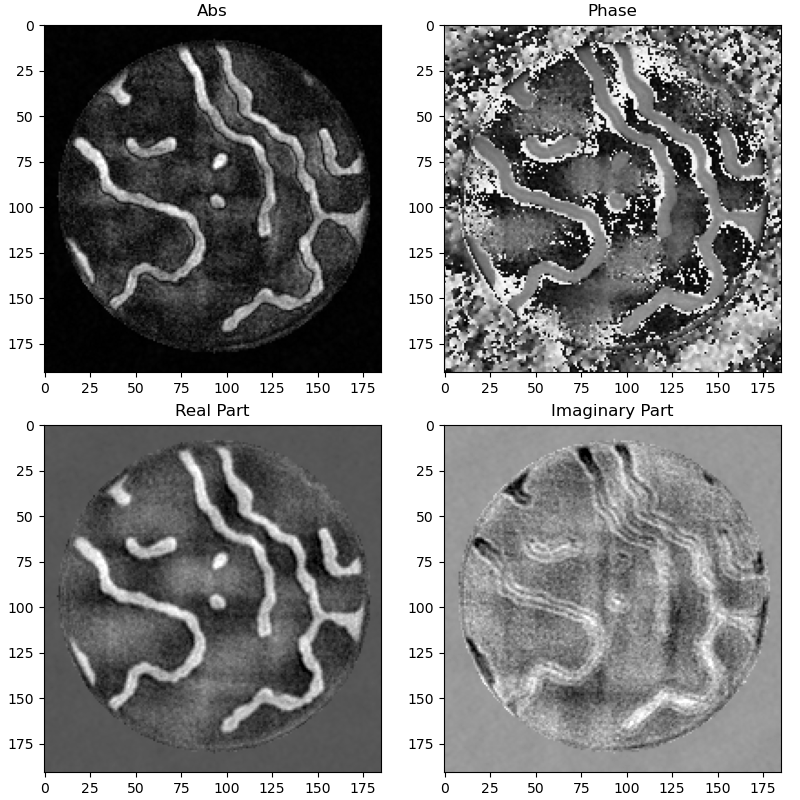

In [101]:
# New beamstop for CDI recos
bs_diam_cdi = 35
mask_bs = 1 - cci.circle_mask(
    topo.shape, np.array(topo.shape) / 2, bs_diam_cdi, sigma=4
)
mask_bs = np.ones(pos.shape)  # if you don't want a beamstop

# Get Recos
# Positive helicity
p = fth.reconstructCDI(
    fth.propagate(
        retrieved_p * mask_bs,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)

# Negative helicity
n = fth.reconstructCDI(
    fth.propagate(
        retrieved_n * mask_bs,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)
p = fth.sub_pixel_centering(p, dx, dy)
n = fth.sub_pixel_centering(n, dx, dy)


# Get Recos partial coherence
# Positiv partial coherence
p_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_p_pc * mask_bs,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)

# Negative partial coherence
n_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_n_pc * mask_bs,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)
p_pc = fth.sub_pixel_centering(p_pc, dx, dy)
n_pc = fth.sub_pixel_centering(n_pc, dx, dy)

# optimize phase
recon = p - n
recon = p_pc - n_pc  # / (p_pc + n_pc)
_, phase_cdi = optimize_phase_contrast(
    recon, supportmask, method="contrast", prefered_color="black"
)

# Plotting
mode = "-"
slider_prop, slider_phase, slider_dx, slider_dy = rec.focusCDI(
    retrieved_p_pc * mask_bs,
    retrieved_n_pc * mask_bs,
    roi_cdi,
    mask=supportmask,
    phase=phase_cdi,
    dx=dx,
    dy=dy,
    prop_dist=prop_dist_cdi,
    experimental_setup=experimental_setup,
    operation=mode,
    max_prop_dist=10,
    scale=(0.1, 99.9),
)

In [105]:
# Get phase from slider
phase_cdi = slider_phase.value
prop_dist_cdi = slider_prop.value

Text(0.5, 1.0, 'Neg holo mask')

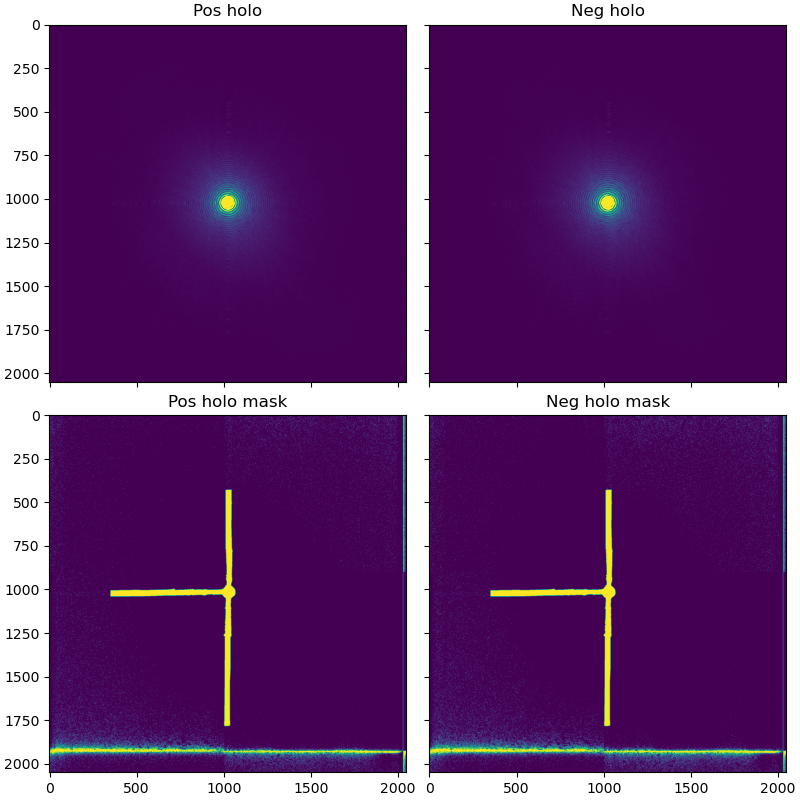

In [104]:
# Confirm that offset subtraction works, i.e., only small fraction of hologram is actually masked
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharex=True, sharey=True)
tmp = np.abs(retrieved_p_pc)
mi, ma = np.percentile(tmp, [0.1, 99.9])
ax[0, 0].imshow(tmp, vmin=mi, vmax=ma)
ax[0, 0].set_title("Pos holo")

tmp = np.abs(retrieved_n_pc)
mi, ma = np.percentile(tmp, [0.1, 99.9])
ax[0, 1].imshow(tmp, vmin=mi, vmax=ma)
ax[0, 1].set_title("Neg holo")
ax[1, 0].imshow(bsmask_p)
ax[1, 0].set_title("Pos holo mask")
ax[1, 1].imshow(bsmask_n)
ax[1, 1].set_title("Neg holo mask")

## Save

In [106]:
# Magnetic field value
data_key = "m_magnett_read"
values = np.mean(np.array(load_data(im_id, data_key)) * 1000)
values = [np.round(values, 2)]

# Cryostat temperature if saved in nxs file
try:
    data_key = "cryob"
    values.append(np.mean(np.array(load_collection(im_id, data_key))))
    title = "Image %d - Diff CDI @%.2f mT, %0.1f K" % (im_id, values[0], values[1])
except:
    title = "Image %d - Diff CDI @%.2f mT" % (im_id, values[0])

Loaded key m_magnett_read of /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01409.nxs
Loaded key cryob of /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01409.nxs


Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Recon_ImId_1409_RefId_1407_cklose_cdi_diff_small.png
Now Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Logs/Data_ImId_1409_RefId_1407_cdi_cklose


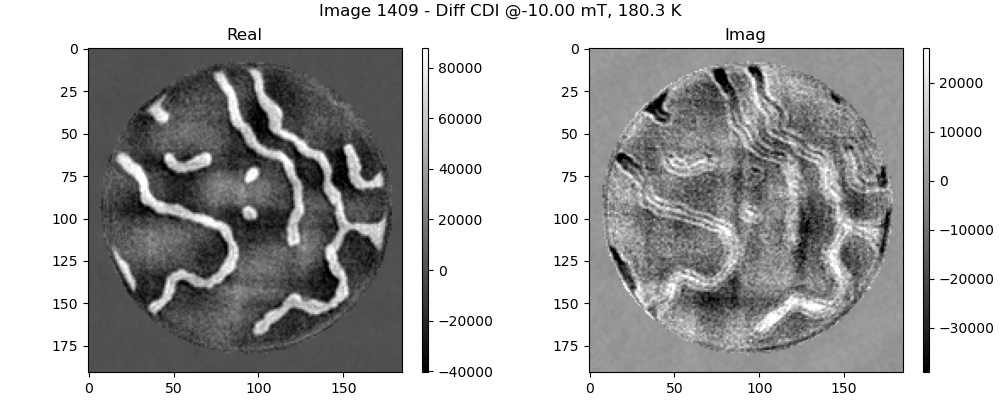

In [107]:
# Saves only real and imaginary part
# Apply phase
p = p * np.exp(1j * phase_cdi)
n = p * np.exp(1j * phase_cdi)
p_pc = p_pc * np.exp(1j * phase_cdi)
n_pc = n_pc * np.exp(1j * phase_cdi)

recon_all = p - n
recon_all = p_pc - n_pc  # / (p_pc + n_pc)
recon = recon_all.copy()

# Plot
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle(title)

vmin, vmax = np.percentile(np.real(recon[roi_cdi]), (0.5, 99.5))
t_im1 = ax[0].imshow(np.real(recon[roi_cdi]), vmin=vmin, vmax=vmax, cmap="gray")
ax[0].set_title("Real")
plt.colorbar(t_im1, ax=ax[0], aspect=50)

vmin, vmax = np.percentile(np.imag(recon[roi_cdi]), (0.5, 99.5))
t_im2 = ax[1].imshow(np.imag(recon[roi_cdi]), vmin=vmin, vmax=vmax, cmap="gray")
ax[1].set_title("Imag")
plt.colorbar(t_im2, ax=ax[1], aspect=50)

# Save images
fname = join(
    folder_general,
    "Recon_ImId_%04d_RefId_%s_%s_cdi_diff_small.png" % (im_id, topo_id, USER),
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

# Save h5
save_cdi_h5()

# Batch processing CDI

## Define Scan Ids

In [108]:
# Laad support mask of which sample?
sample = "s2306a-C1"

In [109]:
# Define the sets for reconstructions. You can make a list or use np.arange
# im_id_set should always have ids of positive helicity holograms,
# topo_id_set those of negative helicity or a proper topo

im_id_set = [1409]
topo_id_set = [1407]  # 1229 * np.ones(len(im_id_set), dtype=int)

# In case of single helicity reconstructions, adapt the helicity
# for contrast inversion
helicity = 1 * np.ones(len(im_id_set), dtype=int)  # [1,-1]

print("Dynamics Set:  %s" % im_id_set)
print("Reference Set: %s" % topo_id_set)
print("Helicity: %s" % helicity)

Dynamics Set:  [1409]
Reference Set: [1407]
Helicity: [1]


## Execute Stack Reconstruction

 
Loaded: /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01427.nxs (2 frames)
Loading imageId: 1427, topoId: 1428
Loaded: /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01428.nxs (2 frames)
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
Shift: [-0.54  0.03]
Linear Fit: 1.0805*x + -58.0848
Now Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Topos/Topo_ImId_1427_RefId_1428_cdi_cklose
Loaded key m_magnett_read of /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01427.nxs
Loaded key cryob of /asap3/petra3/gpfs/p04/2023/data/11019143/raw/FGT/2310_FGT_01427.nxs
Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Recon_ImId_1427_RefId_1428_cklose_fth_diff_stack.png


interactive(children=(FloatRangeSlider(value=(0.0, 1.0), description='contrast', layout=Layout(width='500px'),…

CDI - larger mask
############ -   CDI
--- 8.01 seconds ---
############   -   CDI_pc
--- 36.29 seconds ---
Phase Retrieval Done!
Phase is: 0.52
Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Recon_ImId_1427_RefId_1428_cklose_cdi_diff_stack.png
Now Saving: /asap3/petra3/gpfs/p04/2023/data/11019143/processed/Logs/Data_ImId_1427_RefId_1428_cdi_cklose
CDI stack processing finished


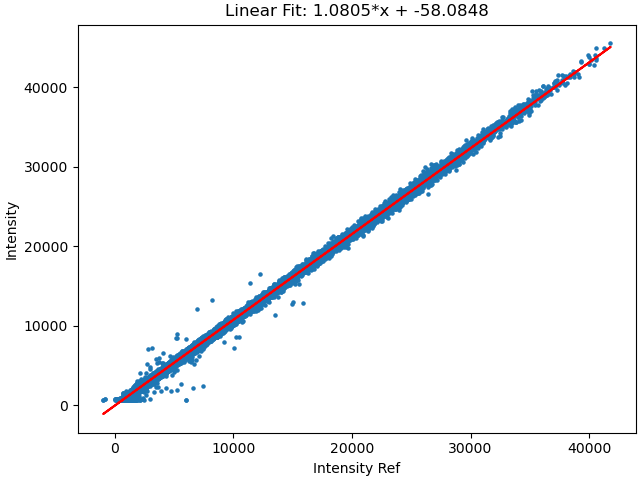

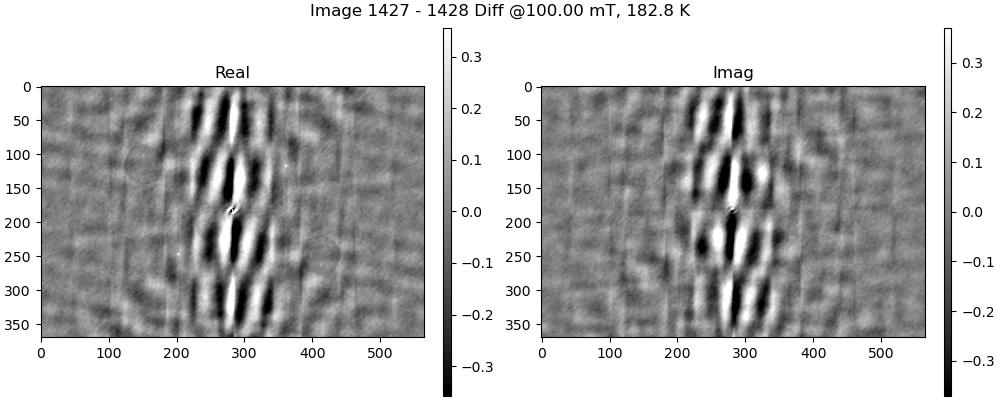

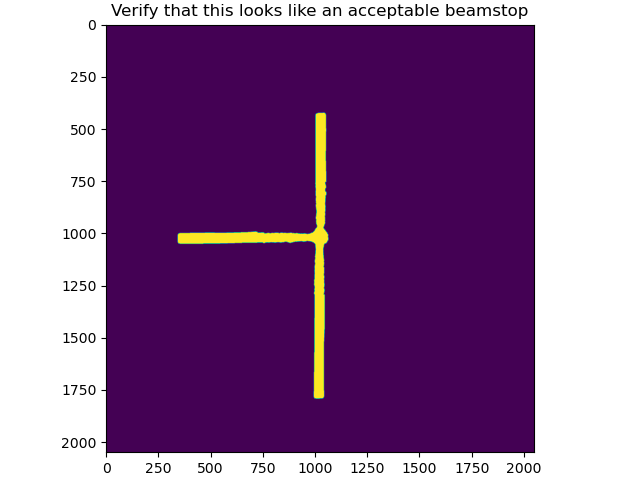

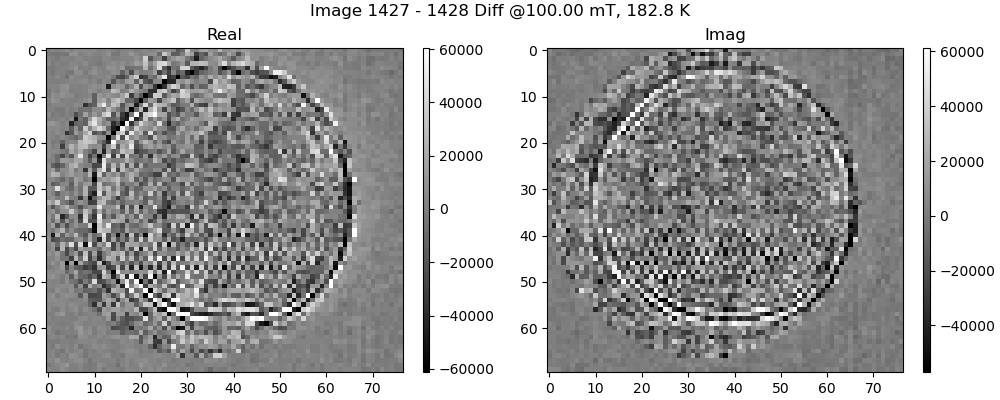

In [245]:
# Ugly Automatic processing of image stacks
recons_name = [] #for gs
for it, im_id in enumerate(im_id_set):
    # Load images
    image, _ = load_processing(im_id)

    # Get topo
    # Do you want to construct topo holo from two helicity images
    try:
        len(topo_id_set[it])
    except:
        # Ordinary case
        # Get also topo & dark id from list of sets
        topo_id = topo_id_set[it]

        # Load data
        print(f"Loading imageId: %04d, topoId: %04d" % (im_id, topo_id))
        topo, _ = load_processing(topo_id)

        # Process images
        worker_dict = worker(image, topo)

        # Save topo hologram
        save_topo_holo(worker_dict["sum_c"], im_id, topo_id)
    else:
        print("Using Topo from sum of two helicity holograms")
        pos_id = topo_id_set[it][0]
        neg_id = topo_id_set[it][1]
        topo_id = topo_id_set[it]

        try:
            topo = load_topo_holo(pos_id, neg_id) / 2
        except:
            topo = load_topo_holo(neg_id, pos_id) / 2
        topo = cci.shift_image(
            topo, -shift_c
        )  # shift out of center so you don't need to change the worker

        # Process images
        worker_dict = worker(image, topo)

    # Save FTH reco
    # Magnetic field value
    data_key = "m_magnett_read"
    values = np.mean(np.array(load_data(im_id, data_key)) * 1000)
    values = [np.round(values, 2)]

    # Cryostat temperature if saved in nxs file
    try:
        data_key = "cryob"
        values.append(np.mean(np.array(load_collection(im_id, data_key))))
        title = "Image %d - %s Diff @%.2f mT, %0.1f K" % (
            im_id,
            topo_id,
            values[0],
            values[1],
        )
    except:
        title = "Image %d - %s Diff @%.2f mT" % (im_id, topo_id, values[0])

    # Reconstruct
    recon = fth.reconstruct(
        fth.propagate(
            worker_dict["holo"], prop_dist * 1e-6, experimental_setup=experimental_setup
        )
        * np.exp(1j * phase)
    )

    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(title)

    vmin, vmax = np.percentile(
        np.real(recon[roi[0] : roi[1], roi[2] : roi[3]]), (1, 99)
    )
    t_im1 = ax[0].imshow(
        np.real(recon[roi[0] : roi[1], roi[2] : roi[3]]),
        vmin=vmin,
        vmax=vmax,
        cmap="gray",
    )
    ax[0].set_title("Real")
    plt.colorbar(t_im1, ax=ax[0], aspect=50)

    vmin, vmax = np.percentile(
        np.imag(recon[roi[0] : roi[1], roi[2] : roi[3]]), (1, 99)
    )
    t_im2 = ax[1].imshow(
        np.imag(recon[roi[0] : roi[1], roi[2] : roi[3]]),
        vmin=vmin,
        vmax=vmax,
        cmap="gray",
    )
    ax[1].set_title("Imag")
    plt.colorbar(t_im2, ax=ax[1], aspect=50)

    # Save images
    fname = join(
        folder_general,
        "Recon_ImId_%04d_RefId_%s_%s_fth_diff_stack.png" % (im_id, topo_id, USER),
    )
    print("Saving: %s" % fname)
    plt.savefig(fname, bbox_inches="tight", transparent=False)

    # Create pos and neg helicity set
    pos = worker_dict["sum_c"] + worker_dict["diff_c"]
    neg = worker_dict["sum_c"] - worker_dict["diff_c"]

    # Start with polygon mask
    polygon_names = ["bs_left_part", "bs_bot_part", "bs_top_part"]
    mask_pixel = load_poly_masks(polygon_names)
    footprint = skimage.morphology.disk(10)
    mask_pixel = skimage.morphology.dilation(mask_pixel, footprint)
    mask_pixel = mask_pixel * (
        1
        - cci.circle_mask(
            pos.shape, [pos.shape[0] / 2, pos.shape[1] / 2], auto_bs.radius
        )
    )

    # Not smooth, pixel mask for CDI only
    mask_pixel = mask_pixel + automated_beamstop(
        pos, auto_bs.thres, auto_bs.radius, auto_bs.expand
    )
    mask_pixel = (
        mask_pixel
        + (topo_c > 65000)
        + (im_c > 65000)
        + cci.circle_mask(pos.shape, [pos.shape[0] / 2, pos.shape[1] / 2], 30)
    )
    mask_pixel[960:983, 1034:1041] = 1
    mask_pixel[mask_pixel > 1] = 1

    fig, ax = cimshow(mask_pixel.astype(int))
    ax.set_title("Verify that this looks like an acceptable beamstop")

    # Get coordinates and create supportmask
    support_coordinates = get_supportmask_coordinates(sample)
    supportmask = create_supportmask(support_coordinates, pos.shape)

    # Do phase retrieval
    (
        retrieved_p,
        retrieved_n,
        retrieved_p_pc,
        retrieved_n_pc,
        bsmask_p,
        bsmask_n,
    ) = phase_retrieval(
        pos, neg, mask_pixel, supportmask, Startimage=Startimage, Startgamma=Startgamma
    )

    # New beamstop for CDI recos
    bs_diam_cdi = 39
    mask_bs_cdi = 1 - cci.circle_mask(
        topo.shape, np.array(topo.shape) / 2, bs_diam_cdi, sigma=4
    )
    # mask_bs_cdi = np.ones(topo.shape)

    # Get Recos partial coherence
    # Positiv partial coherence
    p_pc = fth.reconstructCDI(
        fth.propagate(
            retrieved_p_pc * mask_bs_cdi,
            prop_dist_cdi * 1e-6,
            experimental_setup=experimental_setup,
        )
    )
    # Negative partial coherence
    n_pc = fth.reconstructCDI(
        fth.propagate(
            retrieved_n_pc * mask_bs_cdi,
            prop_dist_cdi * 1e-6,
            experimental_setup=experimental_setup,
        )
    )

    ##### Calc reco and optimze contrast
    recon = helicity[it] * (p_pc - n_pc)
    _, phase_cdi = optimize_phase_contrast(recon, supportmask, method="contrast")
    # phase_cdi = 0
    recon = recon * np.exp(1j * (phase_cdi - 0 * np.pi / 2))
    print("Phase is:", np.round(phase_cdi, 2))
    ########

    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(title)

    vmin, vmax = np.percentile(np.real(recon[roi_cdi]), (0.5, 99.5))
    t_im1 = ax[0].imshow(
        np.real(recon[roi_cdi]),
        vmin=vmin,
        vmax=vmax,
        cmap="gray",
    )
    ax[0].set_title("Real")
    plt.colorbar(t_im1, ax=ax[0], aspect=50)

    vmin, vmax = np.percentile(np.imag(recon[roi_cdi]), (0.5, 99.5))
    t_im2 = ax[1].imshow(np.imag(recon[roi_cdi]), vmin=vmin, vmax=vmax, cmap="gray")
    ax[1].set_title("Imag")
    plt.colorbar(t_im2, ax=ax[1], aspect=50)

    # Save images
    fname = join(
        folder_general,
        "Recon_ImId_%04d_RefId_%s_%s_cdi_diff_stack.png" % (im_id, topo_id, USER),
    )

    print("Saving: %s" % fname)
    plt.savefig(fname, bbox_inches="tight", transparent=False)
    recons_name.append(fname)

    save_cdi_h5()
    
    print(" ")
print("CDI stack processing finished")

In [733]:
plt.close("all")

# Gifs

In [314]:
im_id_set = [
    1268,
    1269,
    1272,
    1273,
    1276,
    1277,
    1280,
    1281,
    1284,
    1285,
    1288,
    1289,
    1292,
    1293,
    1296,
    1297,
    1300,
    1301,
    1303,
    1306,
    1308,
    1313,
    1314,
    1315,
    1316,
    1317,
]
topo_id_set = [
    1267,
    1270,
    1271,
    1274,
    1275,
    1278,
    1279,
    1282,
    1283,
    1286,
    1287,
    1290,
    1291,
    1294,
    1295,
    1298,
    1299,
    1302,
    [1299, 1300],
    1307,
    [1306, 1307],
    1312,
    [1312, 1313],
    [1312, 1313],
    [1312, 1313],
    [1312, 1313],
]

recons_name = []
for i, im_id in enumerate(im_id_set):
    fname = join(
        folder_general,
        "Recon_ImId_%04d_RefId_%s_%s_cdi_diff_stack.png"
        % (im_id, topo_id_set[i], USER),
    )
    recons_name.append(fname)

# Create gif of last scan
var = [imageio.imread(file) for file in recons_name]
fname = f"ImId_%04d_%04d_%s.gif" % (im_id_set[0], im_id_set[-1], USER)
gif_path = path.join(folder_general, fname)
print("Saving gif:%s" % gif_path)
imageio.mimsave(gif_path, var, fps=2)
print("Done!")

Saving gif:/asap3/petra3/gpfs/p04/2023/data/11018117/processed/ImId_1268_1317_cklose.gif
Done!
